# Diagnostica Random Forest Chen — training, testing e generalizzazione (59 funzioni)

**Scopo:** rispondere alle domande del ricevimento, mantenendo congelati **le 14 feature originali**, `RandomForestClassifier(random_state=42)` (senza tuning) e la ground truth GCP. Test per funzione, non per invocazione; tutte le osservazioni di una funzione rimangono nello stesso lato dello split.

**Analisi incluse:** (1) integrità/dataset/etichette; (2) ripetibilità dei profili x86; (3) split K-fold per funzione con metriche sul training e sul testing, per soglie 15% e 2,5%; (4) matrici di confusione e recall delle classi; (5) curve di apprendimento variando il numero di funzioni di training, senza cambiare i parametri RF; (6) elenco delle funzioni critiche e osservazioni sulla ground truth.

**Da distinguere:** il nostro LOFO precedente misura ogni funzione come sconosciuta, mentre K-fold considera più funzioni nuove per test fold. La accuracy **per funzione** usa il voto di maggioranza delle 100 predizioni x86 della stessa funzione; la accuracy **per campione** usa 100 osservazioni ripetute per funzione. Non trattare 5.900 campioni come 5.900 funzioni indipendenti.

**Attenzione:** questa diagnostica NON comprende l'addestramento dei regressori ARM del paper: si concentra sul classificatore ternario. Non cercare/tarare iperparametri a posteriori usando i fold di test.

In [1]:
# Eseguire da ~/Documenti/GitHub/serverledge con .venv-analysis attivo.
from pathlib import Path
import sys, hashlib, json, math, warnings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
from pathlib import Path


REPO = Path.home() / "Documenti/GitHub/serverledge"

os.chdir(REPO)

print("Directory di lavoro:", Path.cwd())

print("Directory corrente:", Path.cwd())
print("Interprete Python:", sys.executable)
print("Ambiente virtuale:", sys.prefix)
print("Repository:", REPO)


assert(REPO / "analysis/profiling/paper_original_prediction_pipeline.py").is_file(), "File del classificatore non trovato"
sys.path.insert(0,str(REPO/'analysis/profiling'))
from paper_original_prediction_pipeline import (load_inputs, DATASET_ROOT, PREDICTORS_14, MODEL_CLASSIFIER, majority_class, CLASSES)
print('RF originale:', RandomForestClassifier(**MODEL_CLASSIFIER).get_params())
print('Feature:', PREDICTORS_14)
print('Dataset:',DATASET_ROOT)

Directory di lavoro: /home/ale/Documenti/GitHub/serverledge
Directory corrente: /home/ale/Documenti/GitHub/serverledge
Interprete Python: /home/ale/Documenti/GitHub/serverledge/.venv-analysis/bin/python3
Ambiente virtuale: /home/ale/Documenti/GitHub/serverledge/.venv-analysis
Repository: /home/ale/Documenti/GitHub/serverledge
RF originale: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Feature: ['totalMemory', 'freeMemory', 'frameworkRuntime', 'userRuntime', 'cpuUserDelta', 'cpuKernelDelta', 'cpuIdleDelta', 'cpuIOWaitDelta', 'cpuSoftIrqDelta', 'cpuStealDelta', 'pageFaultsDelta', 'utilizedCPUs', 'frameworkRuntimeDeltas', 'runt

In [2]:
# I file originali e i loro SHA256 sono controllati da load_inputs.
data,truth,manifest,_ = load_inputs(REPO/DATASET_ROOT)
x86=data.loc[data.machine_tag=='amd64'].copy().reset_index(drop=True)
assert len(x86)==5900 and len(truth)==59 and x86.function_name.nunique()==59
assert (x86.groupby('function_name').size()==100).all()
assert set(x86.function_name)==set(truth.function_name)
assert np.isfinite(x86[PREDICTORS_14].to_numpy(float)).all()
truth_index=truth.set_index('function_name').sort_index()
deltas=truth_index['arm_vs_x86_delta_percent'].astype(float)

def label_from_delta(values, tau):
    a=np.asarray(values,float)
    return np.where(a < -tau,'ARM-faster',np.where(a > tau,'ARM-slower','ARM-similar'))

labels={tau:pd.Series(label_from_delta(deltas.to_numpy(),tau), index=deltas.index)
        for tau in (15.0,2.5)}
assert (labels[15.0] == truth_index['paper_class_15']).all()
assert len(set(x86.function_name))==59
print('Funzioni:',len(truth), '| campioni x86:',len(x86))
for tau,y in labels.items():
    print(f'Soglia ±{tau}%:',y.value_counts().reindex(CLASSES,fill_value=0).to_dict())
print('Ground truth verificata: mediana GCP per funzione, non usata come feature predittiva')

Funzioni: 59 | campioni x86: 5900
Soglia ±15.0%: {'ARM-faster': 11, 'ARM-similar': 40, 'ARM-slower': 8}
Soglia ±2.5%: {'ARM-faster': 26, 'ARM-similar': 9, 'ARM-slower': 24}
Ground truth verificata: mediana GCP per funzione, non usata come feature predittiva


## 1 — Ground truth, margini rispetto alle soglie e stabilità dei profili

La ground truth deriva dalle **mediane della durata effettiva GCP** x86/ARM, che non sono necessariamente uguali al campo `runtime` del profiler SAAF. Qui controlliamo la distanza dalle soglie e la stabilità **dei profili x86** disponibili. Per verificare l'incertezza delle *etichette* con bootstrap delle mediane servirebbero le 100 durate GCP per architettura estratte dalla sorgente originale: **non ricaviamo questa incertezza dal solo runtime del profiler**.

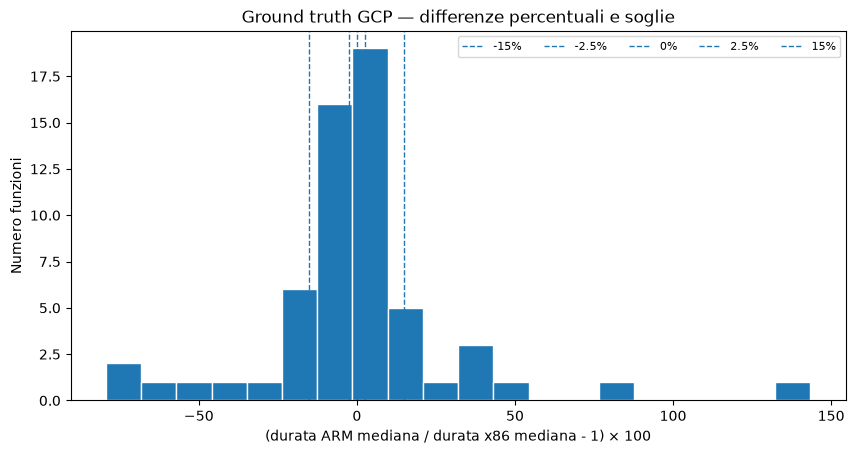

,function_name,threshold,delta_percent,distance_to_threshold_pp,label
112,tempfileio,2.5,-2.818415,0.318415,ARM-faster
117,vswarm-fibonacci,2.5,-2.996542,0.496542,ARM-faster
105,pointerchase,2.5,-3.082013,0.582013,ARM-faster
73,dynamic-html-py,2.5,-3.087469,0.587469,ARM-faster
86,graph-bfs,2.5,-1.912208,0.587792,ARM-similar
63,billibench-kmeans,2.5,-1.805840,0.694160,ARM-similar
106,pointerchase-py,2.5,3.337630,0.837630,ARM-slower
76,float-ops-node,2.5,-3.373384,0.873384,ARM-faster
16,filehandle,15.0,-15.912067,0.912067,ARM-faster
25,functionbench-sequential-disk-io,15.0,15.923312,0.923312,ARM-slower


In [3]:
fig,ax=plt.subplots(figsize=(10,4.8))
ax.hist(deltas,bins=20,edgecolor='white')
for limit in (-15,-2.5,0,2.5,15):ax.axvline(limit,linestyle='--',linewidth=1,label=f'{limit:g}%')
ax.set(xlabel='(durata ARM mediana / durata x86 mediana - 1) × 100',
       ylabel='Numero funzioni',title='Ground truth GCP — differenze percentuali e soglie')
ax.legend(ncol=5,fontsize=8);plt.show()

threshold_rows=[]
for tau in (15.,2.5):
    distance=np.abs(np.abs(deltas)-tau)
    threshold_rows.append(pd.DataFrame({'function_name':deltas.index,'threshold':tau,
        'delta_percent':deltas.to_numpy(),'distance_to_threshold_pp':distance.to_numpy(),
        'label':labels[tau].to_numpy()}))
near=pd.concat(threshold_rows,ignore_index=True)
display(near.sort_values('distance_to_threshold_pp').head(18))

,feature,median_iqr_over_abs_median_pct,functions_constant,functions_with_nonzero_median
8,cpuSoftIrqDelta,200.000000,0,8
7,cpuIOWaitDelta,115.000000,18,4
5,cpuKernelDelta,18.333333,0,54
10,pageFaultsDelta,14.262636,0,59
2,frameworkRuntime,10.114496,0,59
1,freeMemory,9.758435,0,59
12,frameworkRuntimeDeltas,8.280483,0,59
4,cpuUserDelta,2.716926,0,59
6,cpuIdleDelta,2.000000,0,59
13,runtime,1.848139,0,59


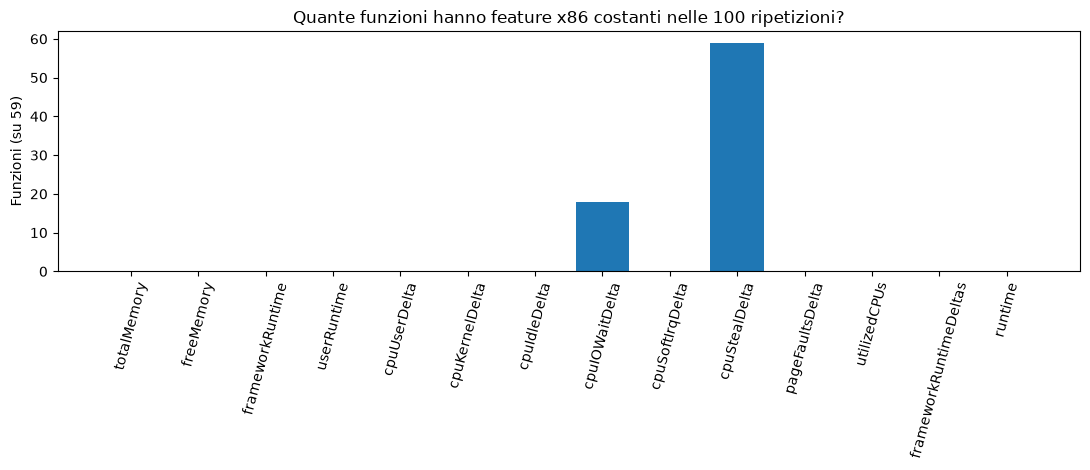

In [4]:
# Ripetibilità delle 100 osservazioni x86: IQR/mediana e quota di feature costanti.
feature_rows=[]
for feat in PREDICTORS_14:
    g=x86.groupby('function_name')[feat]
    q25=g.quantile(.25);q75=g.quantile(.75);median=g.median()
    spread=(q75-q25)/median.abs().replace(0,np.nan)*100
    feature_rows.append({'feature':feat,'median_iqr_over_abs_median_pct':spread.median(),
                         'functions_constant':int((g.nunique()==1).sum()),
                         'functions_with_nonzero_median':int((median!=0).sum())})
feature_spread=pd.DataFrame(feature_rows)
display(feature_spread.sort_values('median_iqr_over_abs_median_pct',ascending=False))
fig,ax=plt.subplots(figsize=(11,4.8))
ax.bar(feature_spread.feature,feature_spread.functions_constant)
ax.tick_params(axis='x',rotation=75)
ax.set(ylabel='Funzioni (su 59)',title='Quante funzioni hanno feature x86 costanti nelle 100 ripetizioni?')
plt.tight_layout();plt.show()

## 2 — Test effettivo per funzione: GroupKFold

**Nessuna fuga d'informazione**: per ogni fold, `set(train_functions) ∩ set(test_functions) = ∅`. Si allena su tutte le 100 osservazioni x86 per ogni funzione di training con l'etichetta della funzione. Il modello rimane esattamente `RandomForestClassifier(random_state=42)`.

Valutiamo anche il training per verificare se il modello riesce a riconoscere i pattern già visti; accuracy training elevata + accuracy test bassa suggerisce sovradattamento, ma **non prova** che l'unica causa sia overfitting. Confrontiamo anche una baseline che predice sempre la classe maggioritaria **del training fold**.

In [5]:
ORDER=list(CLASSES)
GROUPS=x86.function_name.to_numpy()
ALL_IND=np.arange(len(x86))
SPLITS=list(GroupKFold(n_splits=5).split(x86[PREDICTORS_14],groups=GROUPS))
assert all(not(set(GROUPS[tr])&set(GROUPS[te])) for tr,te in SPLITS)

# Voto di maggioranza delle 100 predizioni per funzione (stessa regola del paper).
def collapse_function_votes(frame, predictions, true_lookup):
    temp=pd.DataFrame({'function_name':frame['function_name'].to_numpy(),
                       'prediction':np.asarray(predictions)})
    byfn=temp.groupby('function_name',sort=True)['prediction'].apply(
        lambda s:majority_class(s.to_numpy()))
    true=true_lookup.loc[byfn.index]
    return pd.DataFrame({'function_name':byfn.index,'true':true.to_numpy(),'pred':byfn.to_numpy()})

def get_metrics(frame):
    a=(frame['true']==frame['pred']).to_numpy()
    recalls={f'recall_{cl}':(float((frame.loc[frame.true==cl,'pred']==cl).mean())
                if (frame.true==cl).any() else np.nan) for cl in ORDER}
    valid=np.array(list(recalls.values()),float)
    return {'accuracy':float(a.mean()),'balanced_recall':float(np.nanmean(valid)),**recalls}

cv_rows=[]; cv_pred=[];baseline_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        tr_fn=set(GROUPS[tr]);te_fn=set(GROUPS[te]);assert tr_fn.isdisjoint(te_fn)
        model=RandomForestClassifier(**MODEL_CLASSIFIER)
        model.fit(x86.iloc[tr][PREDICTORS_14],y_all[tr])
        major=pd.Series(y_all[tr]).value_counts().idxmax()
        for split,idx in [('train',tr),('test',te)]:
            sample_predictions=model.predict(x86.iloc[idx][PREDICTORS_14])
            frame=collapse_function_votes(x86.iloc[idx],sample_predictions,y_lookup)
            metrics=get_metrics(frame)
            cv_rows.append({'tau':tau,'fold':fold,'set':split,'n_functions':len(frame),
                            'sample_accuracy':float(np.mean(sample_predictions==y_all[idx])),
                            **metrics})
            cv_pred.append(frame.assign(tau=tau,fold=fold,set=split))
            baseline_rows.append({'tau':tau,'fold':fold,'set':split,
                                  'baseline_majority_class_train':major,
                                  'baseline_function_accuracy':float((frame.true==major).mean())})
cv_results=pd.DataFrame(cv_rows)
cv_predictions=pd.concat(cv_pred,ignore_index=True)
cv_baselines=pd.DataFrame(baseline_rows)
display(cv_results[['tau','fold','set','n_functions','accuracy','sample_accuracy','balanced_recall']])
print('Medie per soglia e split:')
display(cv_results.groupby(['tau','set'])[['accuracy','sample_accuracy','balanced_recall']].agg(['mean','std']).round(4))
print('Baseline sempre-classe-maggioritaria-del-training-fold:')
display(cv_baselines.groupby(['tau','set']).baseline_function_accuracy.mean().round(4))

,tau,fold,set,n_functions,accuracy,sample_accuracy,balanced_recall
0,15.0,1,train,47,1.000000,1.000000,1.000000
1,15.0,1,test,12,0.416667,0.372500,0.238095
2,15.0,2,train,47,1.000000,1.000000,1.000000
3,15.0,2,test,12,0.666667,0.622500,0.458333
4,15.0,3,train,47,1.000000,1.000000,1.000000
5,15.0,3,test,12,0.583333,0.578333,0.291667
6,15.0,4,train,47,1.000000,1.000000,1.000000
7,15.0,4,test,12,0.500000,0.489167,0.285714
8,15.0,5,train,48,1.000000,1.000000,1.000000
9,15.0,5,test,11,0.818182,0.787273,0.450000


Medie per soglia e split:


accuracy         sample_accuracy         balanced_recall        
               mean     std            mean     std            mean     std
tau  set                                                                   
2.5  test    0.3394  0.1565          0.3213  0.1616          0.2759  0.1452
     train   1.0000  0.0000          1.0000  0.0000          1.0000  0.0000
15.0 test    0.5970  0.1548          0.5700  0.1546          0.3448  0.1021
     train   1.0000  0.0000          1.0000  0.0000          1.0000  0.0000

Baseline sempre-classe-maggioritaria-del-training-fold:


tau   set  
2.5   test     0.3909
      train    0.4449
15.0  test     0.6818
      train    0.6782
Name: baseline_function_accuracy, dtype: float64

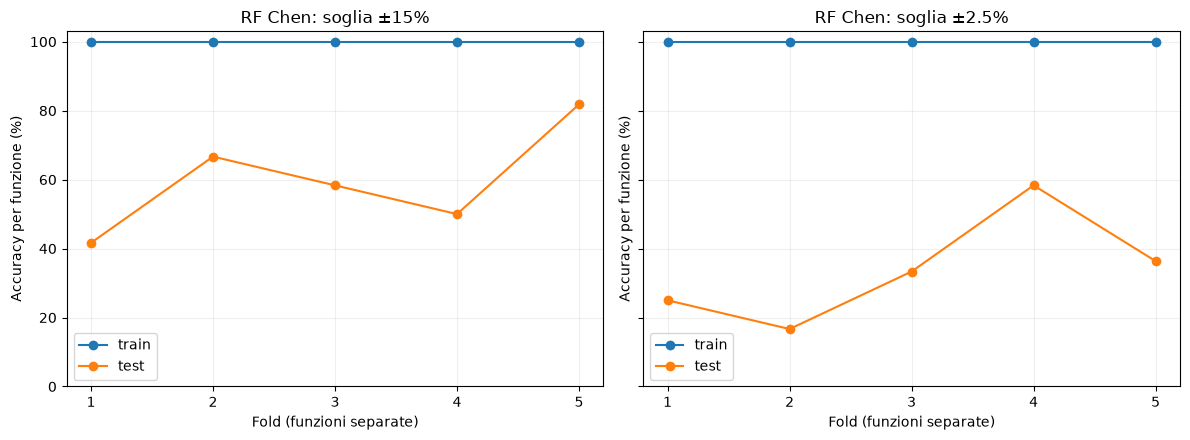

In [6]:
# Grafico 1: accuratezza train/test per ciascun fold.
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    s=cv_results[cv_results.tau==tau]
    for part in ('train','test'):
        z=s[s.set==part].sort_values('fold')
        ax.plot(z.fold,z.accuracy*100,marker='o',label=part)
    ax.set(title=f'RF Chen: soglia ±{tau:g}%',xlabel='Fold (funzioni separate)',
           ylabel='Accuracy per funzione (%)',xticks=[1,2,3,4,5],ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()

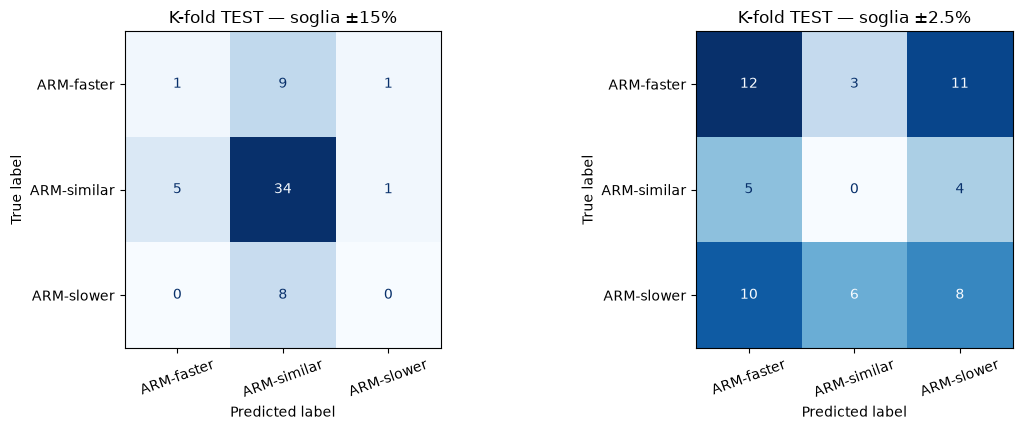

CLASSI TEST, tau=15: {'accuracy': 0.5932203389830508, 'balanced_recall': 0.31363636363636366, 'recall_ARM-faster': 0.09090909090909091, 'recall_ARM-similar': 0.85, 'recall_ARM-slower': 0.0}
Predizioni: {'ARM-faster': 6, 'ARM-similar': 51, 'ARM-slower': 2}
CLASSI TEST, tau=2.5: {'accuracy': 0.3389830508474576, 'balanced_recall': 0.26495726495726496, 'recall_ARM-faster': 0.46153846153846156, 'recall_ARM-similar': 0.0, 'recall_ARM-slower': 0.3333333333333333}
Predizioni: {'ARM-faster': 27, 'ARM-similar': 9, 'ARM-slower': 23}


In [7]:
# Grafico 2: matrici di confusione sui soli dati TEST, ogni funzione una sola volta.
fig,axes=plt.subplots(1,2,figsize=(12,4.4))
for ax,tau in zip(axes,(15.,2.5)):
    oof=cv_predictions[(cv_predictions.tau==tau)&(cv_predictions.set=='test')]
    assert oof.function_name.nunique()==59 and len(oof)==59
    cm=confusion_matrix(oof.true,oof.pred,labels=ORDER)
    ConfusionMatrixDisplay(cm,display_labels=ORDER).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(f'K-fold TEST — soglia ±{tau:g}%')
    ax.tick_params(axis='x',rotation=20)
plt.tight_layout();plt.show()

# Recall per classe della valutazione fuori campione.
for tau in (15.,2.5):
    oof=cv_predictions[(cv_predictions.tau==tau)&(cv_predictions.set=='test')]
    print(f'CLASSI TEST, tau={tau:g}:',get_metrics(oof))
    print('Predizioni:',oof.pred.value_counts().reindex(ORDER,fill_value=0).to_dict())

## 3 — Curve di apprendimento: numero di funzioni di training

Manteniamo *fisso* il gruppo di test di ciascun fold; riduciamo soltanto il numero di funzioni nel training (senza cambiare nessun parametro RF). Una sottoselezione deterministica per fold e per dimensione produce un grafico descrittivo. **Non usiamo queste curve per selezionare una configurazione RF**: servono a capire se il problema diminuisce aumentando le funzioni distinte in training.

Per prove definitive più robuste si potranno aggiungere più estrazioni casuali di gruppi, sempre mantenendo separati i test fold.

mean    std
tau  n_train_functions set                
2.5  8                 test   0.442  0.166
                       train  1.000  0.000
     16                test   0.409  0.237
                       train  1.000  0.000
     24                test   0.371  0.159
                       train  1.000  0.000
     32                test   0.339  0.103
                       train  1.000  0.000
     40                test   0.305  0.150
                       train  1.000  0.000
     47                test   0.339  0.156
                       train  1.000  0.000
15.0 8                 test   0.479  0.172
                       train  1.000  0.000
     16                test   0.495  0.158
                       train  1.000  0.000
     24                test   0.542  0.172
                       train  1.000  0.000
     32                test   0.541  0.084
                       train  1.000  0.000
     40                test   0.511  0.165
                       train  1.000  0.000
     47                test   0.579  0.125
                       train  1.000  0.000

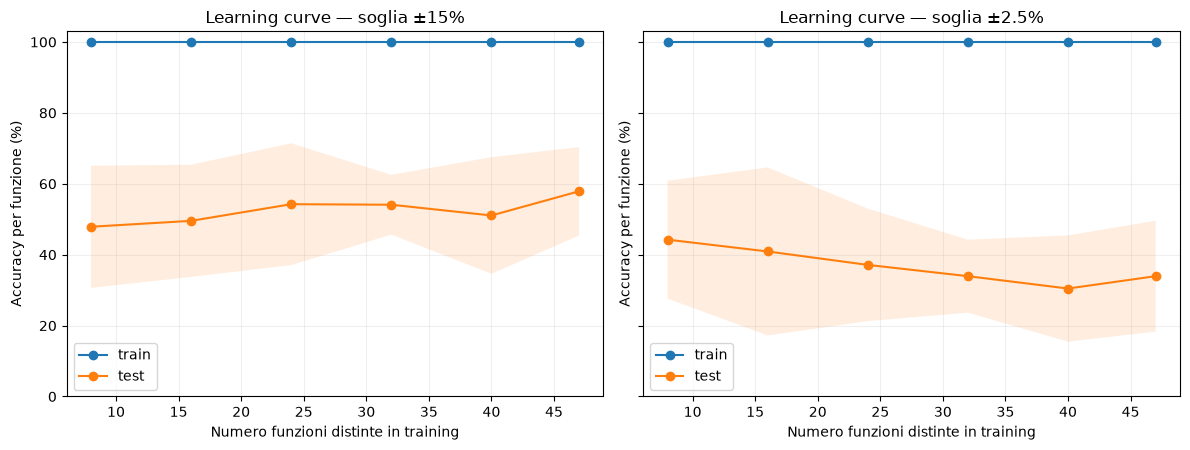

In [8]:
sizes=(8,16,24,32,40,47)
curve_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    all_y=x86.function_name.map(y_lookup).to_numpy()
    for fold,(train_all,test_idx) in enumerate(SPLITS,1):
        fn_train=np.array(sorted(set(GROUPS[train_all])))
        train_set=set(fn_train)
        for n in sizes:
            if n>len(fn_train):continue
            rng=np.random.default_rng(20261029+int(tau*10)*10000+fold*100+n)
            selected=set(rng.choice(fn_train,size=n,replace=False))
            idx=np.array([i for i in train_all if GROUPS[i] in selected])
            assert selected.issubset(train_set) and selected.isdisjoint(set(GROUPS[test_idx]))
            model=RandomForestClassifier(**MODEL_CLASSIFIER)
            model.fit(x86.iloc[idx][PREDICTORS_14],all_y[idx])
            for name,idx2 in [('train',idx),('test',test_idx)]:
                pred=model.predict(x86.iloc[idx2][PREDICTORS_14])
                f=collapse_function_votes(x86.iloc[idx2],pred,y_lookup)
                curve_rows.append({'tau':tau,'fold':fold,'n_train_functions':n,
                                   'set':name,'accuracy_function':get_metrics(f)['accuracy'],
                                   'n_test_functions':len(set(GROUPS[test_idx])),
                                   'classes_in_train':len(set(all_y[idx]))})
learning=pd.DataFrame(curve_rows)
display(learning.groupby(['tau','n_train_functions','set']).accuracy_function.agg(['mean','std']).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.6),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    for split in ('train','test'):
        sub=(learning[(learning.tau==tau)&(learning.set==split)]
             .groupby('n_train_functions').accuracy_function.agg(['mean','std']).reset_index())
        x=sub.n_train_functions.to_numpy()
        mean=sub['mean'].to_numpy()*100
        std=sub['std'].fillna(0).to_numpy()*100
        ax.plot(x,mean,marker='o',label=split)
        ax.fill_between(x,np.maximum(0,mean-std),np.minimum(100,mean+std),alpha=.13)
    ax.set(title=f'Learning curve — soglia ±{tau:g}%',xlabel='Numero funzioni distinte in training',
           ylabel='Accuracy per funzione (%)',ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()

## 4 — Errori e conclusioni verificabili

La tabella seguente mostra *quali* funzioni sono sbagliate nel K-fold; gli errori si confrontano con le distanze dalle soglie (funzioni borderline), senza utilizzare la ground truth per prendere decisioni nel training.

**Regole interpretative:** training alto / test basso = possibile overfitting/generalizzazione insufficiente; training e test entrambi bassi = dati poco separabili, modello incapace di apprendere, class imbalance o feature poco informative; test scarso sulle classi minori = verificare matrice di confusione. Nessuna di queste inferenze è una prova causale autonoma.

In [9]:
oof=cv_predictions[cv_predictions.set=='test'].copy()
oof['correct']=oof.true==oof.pred
oof=oof.merge(near.rename(columns={'threshold':'tau'})[['function_name','tau','delta_percent','distance_to_threshold_pp']],
              on=['function_name','tau'],validate='many_to_one')
print('Errori fuori campione per soglia (prima i casi vicini alla soglia):')
display(oof[~oof.correct].sort_values(['tau','distance_to_threshold_pp'])[
    ['tau','function_name','true','pred','delta_percent','distance_to_threshold_pp']].head(35))
print('Accuracy sui test grouped K-fold:',oof.groupby('tau').correct.mean())
print('Non equiparare questo numero all accuracy LOFO o al 93,35% pubblicato da Chen: dataset e protocollo diversi.')

Errori fuori campione per soglia (prima i casi vicini alla soglia):


,tau,function_name,true,pred,delta_percent,distance_to_threshold_pp
69,2.5,tempfileio,ARM-faster,ARM-slower,-2.818415,0.318415
92,2.5,pointerchase,ARM-faster,ARM-slower,-3.082013,0.582013
109,2.5,dynamic-html-py,ARM-faster,ARM-slower,-3.087469,0.587469
76,2.5,graph-bfs,ARM-similar,ARM-faster,-1.912208,0.587792
107,2.5,billibench-kmeans,ARM-similar,ARM-slower,-1.805840,0.694160
60,2.5,compression,ARM-slower,ARM-faster,3.480706,0.980706
71,2.5,base64stream,ARM-similar,ARM-faster,1.470475,1.029525
62,2.5,float-ops-py,ARM-slower,ARM-faster,3.533319,1.033319
94,2.5,thumbnailer-py,ARM-slower,ARM-faster,3.557465,1.057465
89,2.5,graph-mst-py,ARM-slower,ARM-faster,3.581052,1.081052


Accuracy sui test grouped K-fold: tau
2.5     0.338983
15.0    0.593220
Name: correct, dtype: float64
Non equiparare questo numero all accuracy LOFO o al 93,35% pubblicato da Chen: dataset e protocollo diversi.


In [10]:
# Export FACOLTATIVO: non sovrascrive i risultati congelati.
EXPORT = False
OUT = REPO/'data/architecture-comparison/diagnostics/rf-train-test-kfold-59-v1'
if EXPORT:
    if OUT.exists():
        raise FileExistsError(f'Destinazione gia presente: {OUT}; non sovrascrivo')
    OUT.mkdir(parents=True,exist_ok=False)
    cv_results.to_csv(OUT/'cv_train_test_metrics.csv',index=False)
    cv_predictions.to_csv(OUT/'cv_train_test_by_function.csv',index=False)
    cv_baselines.to_csv(OUT/'cv_baselines.csv',index=False)
    learning.to_csv(OUT/'learning_curves.csv',index=False)
    feature_spread.to_csv(OUT/'feature_stability_x86.csv',index=False)
    near.to_csv(OUT/'distance_from_threshold.csv',index=False)
    oof.to_csv(OUT/'cv_test_errors.csv',index=False)
    (OUT/'methodology.json').write_text(json.dumps({
        'dataset_manifest_sha256':hashlib.sha256((REPO/DATASET_ROOT/'dataset_manifest.json').read_bytes()).hexdigest(),
        'classification_features':PREDICTORS_14,
        'rf_params':MODEL_CLASSIFIER,
        'split':'GroupKFold(n_splits=5), groups=function_name',
        'learning_curve_sizes_functions':list(sizes),
        'note':'No tuning, no ARM target leakage, per-function vote, target label for evaluation only.'
    },indent=2)+'\n',encoding='utf-8')
    print('Creati CSV:',OUT)
else:
    print('Analisi completata in memoria. Imposta EXPORT=True solo per esportare in una cartella nuova.')

Analisi completata in memoria. Imposta EXPORT=True solo per esportare in una cartella nuova.


## 5 — Domande da portare ai professori

1. Qual è il divario tra accuracy training e test sulle 59 funzioni? Cambia fra 15% e 2,5%?
2. La RF supera la baseline della classe maggioritaria **nel test per funzione**?
3. Aumentando il numero di funzioni distinte in training, l'accuracy test migliora?
4. Quali classi e quali funzioni generano gli errori? Sono vicine alla soglia oppure lontane?
5. Le feature x86 presentano realmente informazione discriminante inter-funzione? Le osservazioni risultano stabili?
6. **Controllo successivo dei campioni ARM**: dalla sorgente delle 100 durate native, verificare robustezza delle mediane/etichette con bootstrap per funzione e architettura (non usare `runtime` del profiler come surrogato della duration GCP).

**Non cambiare feature, modello o iperparametri sulla base dei dati di test prima di concordare un protocollo nuovo.**

## 6 — Prova A: quanti campioni per funzione servono davvero?

Manteniamo **RandomForestClassifier(**MODEL_CLASSIFIER)** invariato (14 feature, random_state=42).

Per ogni fold *GroupKFold* già definito, addestriamo su **1, 5, 10, 25, 50 o 100 osservazioni x86 per funzione**. Tutte le funzioni del test restano interamente fuori dal training; in test utilizziamo sempre le **100 osservazioni per funzione**. Ripetiamo la sottoselezione casuale.

L'obiettivo è diagnosticare l'effetto della ridondanza delle osservazioni, **non** selezionare retroattivamente il numero che massimizza il test. I risultati sono esplorativi: se una quantità viene scelta dopo aver esaminato il test, occorre una successiva valutazione indipendente.

**Avvertenza:** questa sezione avvia diversi addestramenti; nessun file è modificato.

,tau,n_samples_per_function,split,count,mean,std
0,2.5,1,test,10,0.3811,0.1254
1,2.5,1,train,10,1.0000,0.0000
2,2.5,5,test,10,0.3720,0.0652
3,2.5,5,train,10,1.0000,0.0000
4,2.5,10,test,10,0.3553,0.0920
5,2.5,10,train,10,1.0000,0.0000
6,2.5,25,test,10,0.3477,0.1222
7,2.5,25,train,10,1.0000,0.0000
8,2.5,50,test,10,0.3227,0.0966
9,2.5,50,train,10,1.0000,0.0000


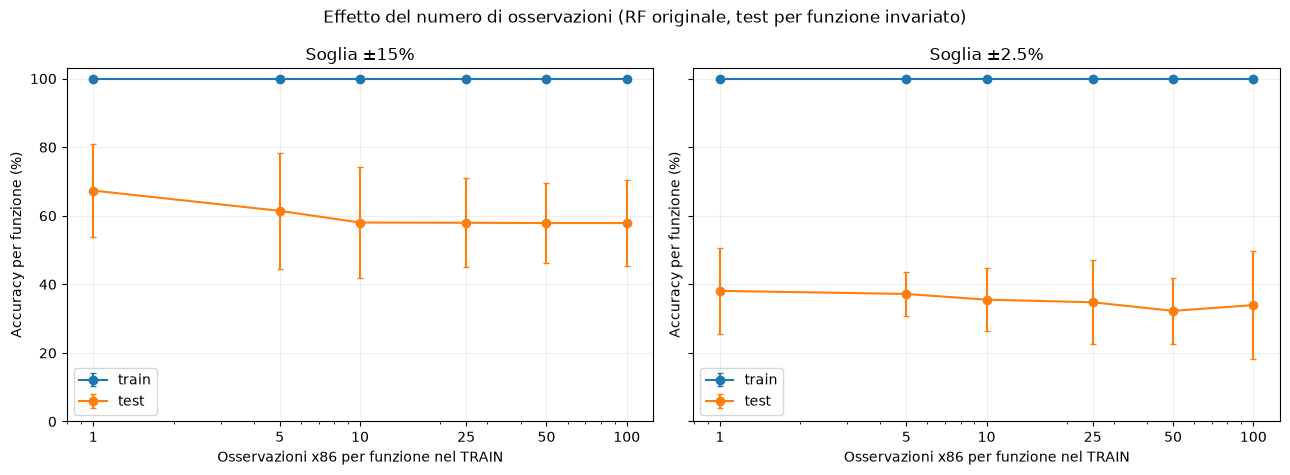

PASS: campionamento per funzione, 100 osservazioni/funzione invarianti in TEST


In [11]:
# 2 ripetizioni e 5 GroupKFold: confronto sulla stessa identica popolazione di test.
from collections import Counter
SAMPLE_LEVELS=(1,5,10,25,50,100)
SAMPLE_REPEATS=2
thin_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        sub=x86.iloc[tr]
        train_fns=sorted(sub.function_name.unique())
        assert not(set(train_fns)&set(x86.iloc[te].function_name.unique()))
        fn_indices={fn:np.flatnonzero(GROUPS==fn) for fn in train_fns}
        assert all(len(ii)==100 for ii in fn_indices.values())
        for nobs in SAMPLE_LEVELS:
            for repeat in range(SAMPLE_REPEATS if nobs < 100 else 1):
                rng=np.random.default_rng(20261029+int(tau*10)*10000+fold*100+nobs*7+repeat)
                idx=np.concatenate([rng.choice(fn_indices[fn], size=nobs,replace=False) for fn in train_fns])
                assert set(idx).issubset(set(tr)) and not(set(idx)&set(te))
                model=RandomForestClassifier(**MODEL_CLASSIFIER)
                model.fit(x86.iloc[idx][PREDICTORS_14],y_all[idx])
                for split,where in [('train',idx),('test',te)]:
                    preds=model.predict(x86.iloc[where][PREDICTORS_14])
                    per_fn=collapse_function_votes(x86.iloc[where],preds,y_lookup)
                    stats=get_metrics(per_fn)
                    thin_rows.append(dict(tau=tau,fold=fold,n_samples_per_function=nobs,
                                         repeat=repeat,split=split,
                                         n_train_functions=len(train_fns),
                                         n_test_functions=len(set(GROUPS[te])),
                                         accuracy_function=stats['accuracy'],
                                         balanced_recall=stats['balanced_recall'],
                                         sample_accuracy=float(np.mean(preds==y_all[where])),
                                         **{f'recall_{k.replace("-","_")}':stats[f'recall_{k}'] for k in CLASSES}))
thinning=pd.DataFrame(thin_rows)
assert len(thinning) == 2*5*(5*2+1)*2
summ_thinning=(thinning.groupby(['tau','n_samples_per_function','split'])
               .accuracy_function.agg(['count','mean','std']).reset_index())
display(summ_thinning.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    for split in ['train','test']:
        s=summ_thinning[(summ_thinning.tau==tau)&(summ_thinning.split==split)]
        ax.errorbar(s.n_samples_per_function,s['mean']*100,
                    yerr=s['std'].fillna(0)*100,marker='o',capsize=2,label=split)
    ax.set(xscale='log',xticks=SAMPLE_LEVELS,xticklabels=SAMPLE_LEVELS,
           xlabel='Osservazioni x86 per funzione nel TRAIN',
           title=f'Soglia ±{tau:g}%',ylabel='Accuracy per funzione (%)',ylim=(0,103))
    ax.legend();ax.grid(alpha=.2)
fig.suptitle('Effetto del numero di osservazioni (RF originale, test per funzione invariato)')
plt.tight_layout();plt.show()
print('PASS: campionamento per funzione, 100 osservazioni/funzione invarianti in TEST')

## 7 — Prova B: learning curve con più sottoselezioni

La precedente learning curve utilizza **una sola** sottoselezione per dimensione e fold. Qui ripetiamo le sottoselezioni indipendenti mantenendo **fissi i cinque gruppi di testing**, sempre sconosciuti al training. Il risultato indica quanto una curva dipenda dalla particolare scelta delle funzioni disponibili, non fornisce un nuovo test indipendente. Non si fa tuning.

I valori medi vanno letti insieme alla variabilità fra i tentativi e confrontati con la baseline del fold.

,tau,n_train_functions,accuracy_mean,accuracy_std,baseline_mean,balanced_recall_mean,runs
0,2.5,8,0.3960,0.1233,0.4343,0.3295,15
1,2.5,24,0.2990,0.1248,0.3843,0.2821,15
2,2.5,40,0.3768,0.1752,0.3798,0.3205,15
3,2.5,47,0.3333,0.1457,0.3788,0.2714,15
4,15.0,8,0.5227,0.1399,0.6818,0.3699,15
5,15.0,24,0.5328,0.1281,0.6818,0.3561,15
6,15.0,40,0.5308,0.0766,0.6818,0.3217,15
7,15.0,47,0.5909,0.1350,0.6818,0.3414,15


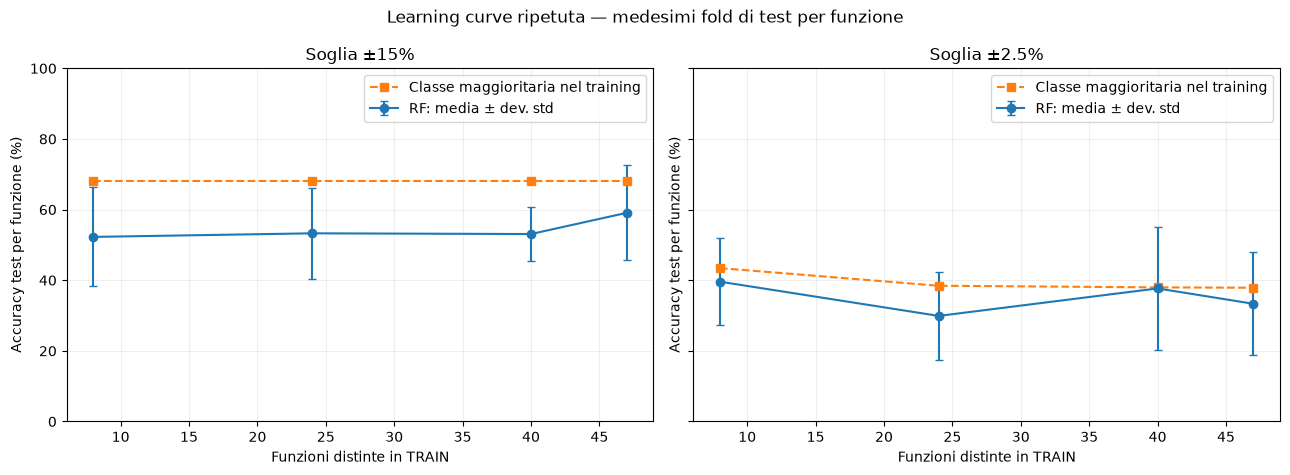

PASS: nessuna funzione di test è stata usata per addestrare RF


In [12]:
REPEATED_SIZES=(8,24,40,47)
REPEATED_SUBSETS=3
repeat_curve_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for fold,(tr,te) in enumerate(SPLITS,1):
        funcs=np.array(sorted(set(GROUPS[tr])))
        for n_fn in REPEATED_SIZES:
            assert n_fn <= len(funcs)
            for rep in range(REPEATED_SUBSETS):
                rng=np.random.default_rng(20261030+int(tau*10)*10000+fold*10000+n_fn*33+rep)
                chosen=set(rng.choice(funcs,size=n_fn,replace=False))
                ind=np.asarray([i for i in tr if GROUPS[i] in chosen])
                assert len(ind)==100*n_fn and not(set(GROUPS[te])&chosen)
                model=RandomForestClassifier(**MODEL_CLASSIFIER)
                model.fit(x86.iloc[ind][PREDICTORS_14],y_all[ind])
                pred=model.predict(x86.iloc[te][PREDICTORS_14])
                frame=collapse_function_votes(x86.iloc[te],pred,y_lookup)
                stats=get_metrics(frame)
                major=pd.Series(y_all[ind]).value_counts().idxmax()
                repeat_curve_rows.append(dict(tau=tau,fold=fold,rep=rep,
                    n_train_functions=n_fn,n_test_functions=len(frame),
                    classes_in_train=len(set(y_all[ind])),
                    accuracy_test=stats['accuracy'],
                    balanced_recall_test=stats['balanced_recall'],
                    majority_baseline_test=float((frame.true==major).mean())))
rep_curve=pd.DataFrame(repeat_curve_rows)
assert len(rep_curve)==2*5*len(REPEATED_SIZES)*REPEATED_SUBSETS
summ_rep=(rep_curve.groupby(['tau','n_train_functions'])
          .agg(accuracy_mean=('accuracy_test','mean'),accuracy_std=('accuracy_test','std'),
               baseline_mean=('majority_baseline_test','mean'),
               balanced_recall_mean=('balanced_recall_test','mean'),runs=('accuracy_test','size'))
          .reset_index())
display(summ_rep.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharey=True)
for ax,tau in zip(axes,(15.,2.5)):
    s=summ_rep[summ_rep.tau==tau]
    ax.errorbar(s.n_train_functions,s.accuracy_mean*100,
                yerr=s.accuracy_std.fillna(0)*100,marker='o',capsize=3,label='RF: media ± dev. std')
    ax.plot(s.n_train_functions,s.baseline_mean*100,linestyle='--',marker='s',
            label='Classe maggioritaria nel training')
    ax.set(title=f'Soglia ±{tau:g}%',xlabel='Funzioni distinte in TRAIN',
           ylabel='Accuracy test per funzione (%)',ylim=(0,100))
    ax.legend();ax.grid(alpha=.2)
fig.suptitle('Learning curve ripetuta — medesimi fold di test per funzione')
plt.tight_layout();plt.show()
print('PASS: nessuna funzione di test è stata usata per addestrare RF')

## 8 — Bootstrap della ground truth GCP (CSV originali)

La campagna ha conservato gli `experiment_results.csv` per architettura, round e funzione. Ogni CSV registra la durata **server-side** `duration_s` (secondi), oltre ai flag `is_warm_start`, `execution_succeeded`, `profile_valid` ed `exclusive_container`. Non si usa `locust_response_time_ms` né la feature `runtime`.

Ricostruiamo **5 round × 20 campioni warm/validi** per ciascuna delle 59 funzioni e per ciascuna architettura. Prima di qualsiasi bootstrap controlliamo conteggi, provenance e corrispondenza numerica delle mediane con la ground truth congelata. Se qualcosa non coincide, ci fermiamo per diagnosticare la selezione, senza forzare i risultati.


In [13]:
# STEP C1 — Ricostruzione verificata dei 100 tempi originali per funzione/architettura.
# Non sostituire duration_s con locust_response_time_ms o con la feature runtime.
from collections import defaultdict
import csv

RAW_DIR = REPO / 'data/profiling/gcp-paper-rf-schema6/campaign/paper_rf_schema6_final/blocks'
assert RAW_DIR.is_dir(), f'Cartella non trovata: {RAW_DIR}'
raw_files = sorted(RAW_DIR.glob('*/round_*/*/experiment_results.csv'))
print('CSV originali trovati:', len(raw_files))
assert raw_files, 'Nessun experiment_results.csv: non si può procedere al bootstrap.'

expected_fns = set(truth_index.index)
ARCHS = ('amd64', 'arm64')
ROUNDS = {f'round_{i:03d}' for i in range(5)}
expected_keys = {(fn, arch) for fn in expected_fns for arch in ARCHS}

all_durations = defaultdict(list)
blocks_seen = set()
block_rows = []

required_fields = {
    'function', 'sample_index', 'duration_s', 'is_warm_start',
    'execution_succeeded', 'node_arch', 'status_code', 'policy',
    'profile_valid', 'exclusive_container'
}

def yes(value):
    return str(value).strip().lower() == 'true'

for path in raw_files:
    relative = path.relative_to(RAW_DIR)
    if len(relative.parts) != 4:
        raise ValueError(f'Layout non riconosciuto: {relative}')
    arch, round_name, fn, filename = relative.parts
    assert arch in ARCHS, (relative, arch)
    assert round_name in ROUNDS, f'Round fuori protocollo: {relative}'
    assert filename == 'experiment_results.csv', relative
    # Le eventuali altre 8 funzioni non partecipano al confronto comune-59.
    if fn not in expected_fns:
        continue
    block_key = (fn, arch, round_name)
    assert block_key not in blocks_seen, f'Blocco duplicato: {block_key}'
    blocks_seen.add(block_key)
    n_rows = 0
    selected = []
    with path.open(newline='', encoding='utf-8') as handle:
        reader = csv.DictReader(handle)
        missing = required_fields - set(reader.fieldnames or ())
        assert not missing, f'Colonne mancanti {missing}: {relative}'
        for row in reader:
            n_rows += 1
            assert row['function'] == fn, f'Funzione errata: {relative}, {row["function"]}'
            assert row['node_arch'] == arch, f'Architettura errata: {relative}, {row["node_arch"]}'
            # Non considerare cold, errori, profili incompleti/non esclusivi.
            valid = (yes(row['is_warm_start']) and
                     yes(row['execution_succeeded']) and
                     yes(row['profile_valid']) and
                     yes(row['exclusive_container']) and
                     str(row['status_code']).strip() == '200')
            if not valid:
                continue
            assert row['policy'] == 'RoundRobin', (relative, row['policy'])
            seconds = float(row['duration_s'])
            assert np.isfinite(seconds) and seconds > 0, (relative, seconds)
            selected.append(seconds * 1000.0)  # seconds -> milliseconds
    block_rows.append({'function_name': fn, 'machine_tag': arch,
                       'round': round_name, 'total_rows': n_rows,
                       'selected_warm_valid': len(selected)})
    # Ogni round della campagna finale ha 20 campioni selezionati, non 20 righe arbitrarie.
    if len(selected) != 20:
        print(f'BLOCCO NON CONFORME: {relative} | righe={n_rows} | validi={len(selected)}')
        raise ValueError('Conteggio warm/validi inatteso: confrontare con la selezione della campagna')
    all_durations[(fn, arch)].extend(selected)

block_summary = pd.DataFrame(block_rows)
expected_blocks = {(fn, a, rnd) for fn, a in expected_keys for rnd in ROUNDS}
assert blocks_seen == expected_blocks, (
    f'Blocchi trovati {len(blocks_seen)} contro {len(expected_blocks)}; '
    f'mancanti={sorted(expected_blocks-blocks_seen)[:10]}')
assert len(block_summary) == 59 * 2 * 5
wrong_counts = {(fn, arch):len(all_durations[(fn,arch)]) for fn,arch in expected_keys
                if len(all_durations[(fn,arch)]) != 100}
assert not wrong_counts, f'Non ci sono 100 campioni per architettura: {list(wrong_counts.items())[:10]}'

# Controllo forte: le mediane ricostruite devono RIPRODURRE quelle congelate.
med_x = np.array([np.median(all_durations[(fn,'amd64')]) for fn in truth_index.index], float)
med_a = np.array([np.median(all_durations[(fn,'arm64')]) for fn in truth_index.index], float)
truth_x = truth_index.x86_median_duration_ms.to_numpy(float)
truth_a = truth_index.arm_median_duration_ms.to_numpy(float)
err_x = float(np.max(np.abs(med_x-truth_x)))
err_a = float(np.max(np.abs(med_a-truth_a)))
print('Blocchi validati:', len(block_summary), '| 100 warm validi per funzione e architettura')
print(f'Errore massimo mediana x86: {err_x:.9g} ms | ARM: {err_a:.9g} ms')
if not np.allclose(med_x, truth_x, rtol=1e-9, atol=1e-6) or not np.allclose(med_a, truth_a, rtol=1e-9, atol=1e-6):
    mismatches = pd.DataFrame({
        'function_name': truth_index.index,
        'x86_original': truth_x, 'x86_csv': med_x,
        'arm_original': truth_a, 'arm_csv': med_a,
        'err_x86': np.abs(med_x-truth_x), 'err_arm': np.abs(med_a-truth_a)
    })
    display(mismatches.nlargest(10, 'err_x86'))
    display(mismatches.nlargest(10, 'err_arm'))
    raise ValueError('Mediane non coincidenti: NON procedere al bootstrap; controllare provenance/selezione')

HAS_RAW_BOOTSTRAP = True
print('PASS: 59 funzioni × 2 architetture × 100 campioni validi; mediane originali confermate')


CSV originali trovati: 670
Blocchi validati: 590 | 100 warm validi per funzione e architettura
Errore massimo mediana x86: 1.8189894e-12 ms | ARM: 4.54747351e-13 ms
PASS: 59 funzioni × 2 architetture × 100 campioni validi; mediane originali confermate


Soglia ±15%: stabilità mediana=1.000; funzioni con agreement<0.95=0/59; agreement<0.8=0/59


,function_name,true_class,delta_percent,bootstrap_label_agreement,delta_boot_ci_low,delta_boot_ci_high
32,filehandle,ARM-faster,-15.9121,0.9565,-16.4182,-14.5769
90,mutexcontention,ARM-similar,11.8860,0.9920,10.8404,14.5961
12,billibench-linear-regression,ARM-similar,-13.2978,0.9940,-14.5131,-12.4367
88,memory-rw-py,ARM-similar,12.6247,0.9995,11.4050,13.6034
0,amd_faster,ARM-slower,40.7256,1.0000,40.4666,41.0533
2,arm_faster,ARM-faster,-16.7392,1.0000,-16.8238,-16.6196
4,base64stream,ARM-similar,1.4705,1.0000,1.3963,1.5889
6,base64stream-py,ARM-similar,-4.7975,1.0000,-5.4089,-4.0097
8,billibench-kmeans,ARM-similar,-1.8058,1.0000,-2.6276,-0.8913
10,billibench-knn,ARM-faster,-61.9320,1.0000,-62.3623,-61.6848


Soglia ±2.5%: stabilità mediana=1.000; funzioni con agreement<0.95=4/59; agreement<0.8=1/59


,function_name,true_class,delta_percent,bootstrap_label_agreement,delta_boot_ci_low,delta_boot_ci_high
107,tempfileio,ARM-faster,-2.8184,0.6830,-5.1305,-0.8325
55,graph-bfs,ARM-similar,-1.9122,0.8120,-3.2494,0.0881
93,pointerchase,ARM-faster,-3.0820,0.8725,-4.2321,-2.0843
87,memory-rw-node,ARM-similar,0.4460,0.8735,-2.2313,4.3872
9,billibench-kmeans,ARM-similar,-1.8058,0.9600,-2.6276,-0.8913
61,graph-mst,ARM-similar,0.7271,0.9620,-0.4684,2.6606
29,dynamic-html-py,ARM-faster,-3.0875,0.9965,-3.3484,-2.8487
63,graph-mst-py,ARM-slower,3.5811,0.9995,2.9672,4.2791
69,graph-pagerank-py,ARM-slower,11.6103,0.9995,7.8187,13.6324
117,vswarm-fibonacci,ARM-faster,-2.9965,0.9995,-3.2556,-2.7253


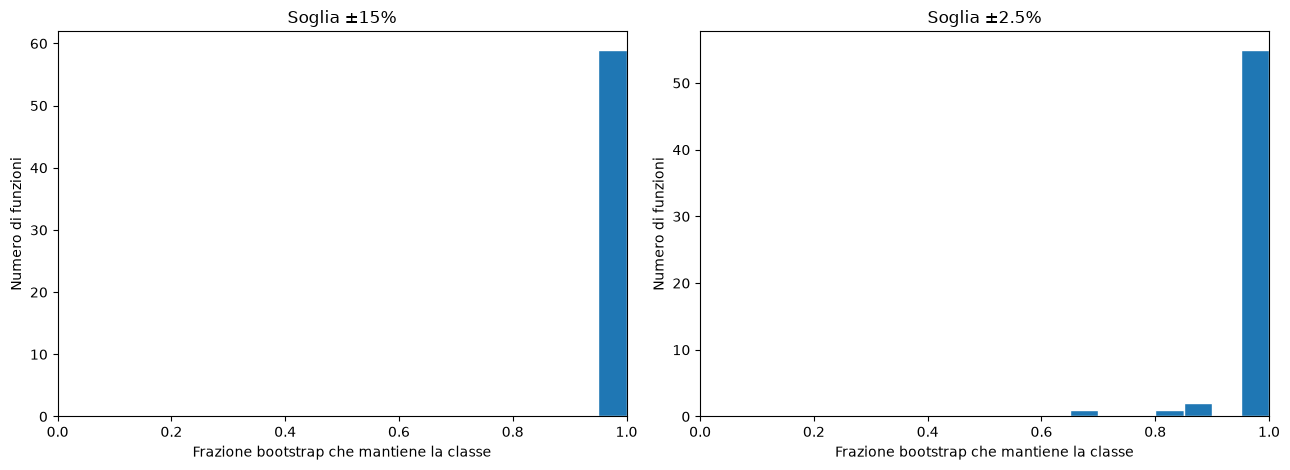

PASS: bootstrap su durate originali GCP; metriche descrittive, nessuna nuova misura


In [14]:
# STEP C2: solo se la provenienza dei 100 tempi per architettura è stata confermata.
if not HAS_RAW_BOOTSTRAP:
    print('SKIP: bootstrap non eseguito perché mancano le durate GCP originali verificate.')
    print('Le analisi RF restano invariate; nessuna stima di stabilità etichette viene inventata.')
else:
    # Eseguire questa cella SOLO dopo il PASS della precedente: nessuna modifica dei dati.
    B=2000
    rng=np.random.default_rng(20261029)
    bootstrap_rows=[]
    for fn in truth_index.index:
        x=np.asarray(all_durations[(fn,'amd64')],float)
        a=np.asarray(all_durations[(fn,'arm64')],float)
        ix=rng.integers(0,100,size=(B,100))
        ia=rng.integers(0,100,size=(B,100))
        boot_x=np.median(x[ix],axis=1)
        boot_a=np.median(a[ia],axis=1)
        boot_delta=100*(boot_a/boot_x-1)
        actual=float(deltas.loc[fn])
        for tau in (15.,2.5):
            nominal=str(label_from_delta([actual],tau)[0])
            boot_labels=label_from_delta(boot_delta,tau)
            counts=pd.Series(boot_labels).value_counts().reindex(CLASSES,fill_value=0)
            bootstrap_rows.append(dict(function_name=fn,tau=tau,delta_percent=actual,
              true_class=nominal,bootstrap_label_agreement=float(np.mean(boot_labels==nominal)),
              delta_boot_ci_low=float(np.quantile(boot_delta,.025)),
              delta_boot_ci_high=float(np.quantile(boot_delta,.975)),
              **{f'prob_{k.replace("-","_")}':float(counts.loc[k]/B) for k in CLASSES}))
    boot_labels_df=pd.DataFrame(bootstrap_rows)
    for tau in (15.,2.5):
        s=boot_labels_df[boot_labels_df.tau==tau]
        print(f'Soglia ±{tau:g}%: stabilità mediana={s.bootstrap_label_agreement.median():.3f}; '
              f'funzioni con agreement<0.95={(s.bootstrap_label_agreement<.95).sum()}/59; '
              f'agreement<0.8={(s.bootstrap_label_agreement<.8).sum()}/59')
        display(s.nsmallest(12,'bootstrap_label_agreement')
                [['function_name','true_class','delta_percent','bootstrap_label_agreement',
                  'delta_boot_ci_low','delta_boot_ci_high']].round(4))
    fig,axes=plt.subplots(1,2,figsize=(13,4.8))
    for ax,tau in zip(axes,(15.,2.5)):
        s=boot_labels_df[boot_labels_df.tau==tau]
        ax.hist(s.bootstrap_label_agreement,bins=np.linspace(0,1,21),edgecolor='white')
        ax.set(title=f'Soglia ±{tau:g}%',xlabel='Frazione bootstrap che mantiene la classe',
               ylabel='Numero di funzioni',xlim=(0,1))
    plt.tight_layout();plt.show()
    print('PASS: bootstrap su durate originali GCP; metriche descrittive, nessuna nuova misura')


### Interpretazione e prossimi passi

- Se TRAIN resta al 100% ma TEST è basso: forte divario di generalizzazione, non automaticamente una causa unica.
- Se meno osservazioni x86 migliorano TEST: indizio di ridondanza/sovradattamento ai profili noti, non prova definitiva; per scegliere la quantità corretta usare una validazione interna.
- Se aumentando funzioni diverse TEST migliora stabilmente: più workload/funzioni possono aiutare; ripetere e riportare la dispersione.
- Se il bootstrap mostra classi instabili: una parte del problema dipende dalla posizione delle funzioni vicino alle soglie.
- Se il bootstrap mostra classi stabili, ma la generalizzazione è bassa: indagare qualità/separabilità delle 14 feature, sbilanciamento e variabilità di hardware/workload.

Per l'eventuale ottimizzazione successiva, mantenere **LOFO o un test esterno per funzione** come valutazione finale. NON selezionare iperparametri usando questi test diagnostici e poi riportarli come stima indipendente.

## 9 — Verifica temporale: i cinque round GCP e bootstrap stratificato

Le 100 osservazioni per architettura derivano da **cinque round × 20 warm valide**. Il bootstrap precedente assume scambiabilità delle 100 durate. Qui controlliamo la variabilità **tra round**, ricalcoliamo la classe per ogni round e ripetiamo il bootstrap rispettando 20 campioni per round. Non cambiamo né le etichette congelate né gli input RF. Le classi per singolo round sono **diagnostiche**, non nuove ground truth.


In [15]:
from collections import Counter
assert HAS_RAW_BOOTSTRAP and len(blocks_seen)==590
round_times={}
for (fn,arch,rnd) in sorted(blocks_seen):
    path=RAW_DIR / arch / rnd / fn / 'experiment_results.csv'
    with path.open(newline='',encoding='utf-8') as f:
        rdr=csv.DictReader(f)
        vals=[]
        for row in rdr:
            ok=(yes(row['is_warm_start']) and yes(row['execution_succeeded'])
                and yes(row['profile_valid']) and yes(row['exclusive_container'])
                and str(row['status_code']).strip()=='200')
            if ok:
                assert row['policy']=='RoundRobin'
                vals.append(1000.0*float(row['duration_s']))
    assert len(vals)==20,(fn,arch,rnd,len(vals))
    round_times[(fn,arch,rnd)]=np.array(vals,dtype=float)
# Verifica che il ricalcolo dei valori per round non alteri i 100 campioni di C1.
for fn in truth_index.index:
    for a in ARCHS:
        v=np.concatenate([round_times[(fn,a,r)] for r in sorted(ROUNDS)])
        assert np.allclose(np.sort(v),np.sort(all_durations[(fn,a)]),atol=1e-10,rtol=1e-12)
round_rows=[]
for fn in truth_index.index:
    for rnd in sorted(ROUNDS):
        med_x=np.median(round_times[(fn,'amd64',rnd)])
        med_a=np.median(round_times[(fn,'arm64',rnd)])
        delta=100*(med_a/med_x-1)
        for tau in (15.,2.5):
            nominal=str(labels[tau].loc[fn])
            actual=str(label_from_delta([delta],tau)[0])
            round_rows.append({'function_name':fn,'round':rnd,'tau':tau,
                               'round_delta_percent':delta,
                               'round_class':actual,'ground_truth_class':nominal,
                               'agrees':int(actual==nominal)})
round_table=pd.DataFrame(round_rows)
round_summary=(round_table.groupby(['tau','function_name'])
               .agg(round_agreement=('agrees','mean'),
                    delta_round_min=('round_delta_percent','min'),
                    delta_round_max=('round_delta_percent','max'))
               .reset_index())
for tau in (15.,2.5):
    s=round_summary[round_summary.tau==tau]
    print(f'±{tau:g}%: funzioni con classe invariata nei 5 round = '
          f'{int((s.round_agreement==1).sum())}/59; con cambio almeno una volta = '
          f'{int((s.round_agreement<1).sum())}/59')
    display(s.sort_values('round_agreement').head(10).round(4))
print('PASS: 5 round distinti × 20 durate per funzione e architettura')


±15%: funzioni con classe invariata nei 5 round = 53/59; con cambio almeno una volta = 6/59


,tau,function_name,round_agreement,delta_round_min,delta_round_max
75,15.0,filehandle,0.4,-18.0678,6.2503
65,15.0,billibench-linear-regression,0.8,-17.3768,-9.1035
93,15.0,graph-pagerank-py,0.8,-2.2649,23.9002
91,15.0,graph-pagerank,0.8,8.8570,41.1753
104,15.0,mutexcontention,0.8,10.9752,15.1226
103,15.0,memory-rw-py,0.8,6.9818,17.0581
61,15.0,base64stream,1.0,0.9782,1.9017
59,15.0,amd_faster,1.0,40.1720,41.2376
67,15.0,compression,1.0,3.1408,4.0055
68,15.0,compression-node,1.0,5.3603,7.8267


±2.5%: funzioni con classe invariata nei 5 round = 41/59; con cambio almeno una volta = 18/59


,tau,function_name,round_agreement,delta_round_min,delta_round_max
43,2.5,memory-rw-node,0.0,-7.6514,13.6685
27,2.5,graph-bfs,0.4,-10.1517,4.9783
18,2.5,float-ops-py,0.6,1.6222,4.4569
4,2.5,billibench-kmeans,0.6,-10.6418,6.2021
30,2.5,graph-mst,0.6,-2.8473,4.8839
31,2.5,graph-mst-py,0.6,2.1062,5.1097
47,2.5,pointerchase-py,0.6,1.8931,4.0341
26,2.5,goroutines,0.6,-2.7012,2.9780
53,2.5,tempfileio,0.6,-10.4684,3.1902
20,2.5,functionbench-float-operation,0.8,-3.9463,-0.1054


PASS: 5 round distinti × 20 durate per funzione e architettura


In [16]:
# Bootstrap stratificato: in ogni replica ricampioniamo 20 osservazioni per round.
B_ROUND=2000
rng_round=np.random.default_rng(20261030)
round_boot_rows=[]
for fn in truth_index.index:
    xx=np.stack([round_times[(fn,'amd64',r)] for r in sorted(ROUNDS)])
    aa=np.stack([round_times[(fn,'arm64',r)] for r in sorted(ROUNDS)])
    ix=rng_round.integers(0,20,size=(B_ROUND,5,20))
    ia=rng_round.integers(0,20,size=(B_ROUND,5,20))
    bx=np.median(np.take_along_axis(xx[None,:,:],ix,axis=2).reshape(B_ROUND,100),axis=1)
    ba=np.median(np.take_along_axis(aa[None,:,:],ia,axis=2).reshape(B_ROUND,100),axis=1)
    bd=100*(ba/bx-1)
    for tau in (15.,2.5):
        nominal=str(labels[tau].loc[fn]); b_lab=label_from_delta(bd,tau)
        round_boot_rows.append({'function_name':fn,'tau':tau,
            'stratified_agreement':float((b_lab==nominal).mean()),
            'stratified_delta_ci_low':float(np.quantile(bd,.025)),
            'stratified_delta_ci_high':float(np.quantile(bd,.975))})
round_boot=pd.DataFrame(round_boot_rows)
comparison=round_boot.merge(boot_labels_df[['function_name','tau','bootstrap_label_agreement']],
                            on=['function_name','tau'],validate='one_to_one')
for tau in (15.,2.5):
    s=comparison[comparison.tau==tau].copy()
    print(f'±{tau:g}%: agreement <95%: '
          f"bootstrap semplice={int((s.bootstrap_label_agreement<.95).sum())}, "
          f"stratificato per round={int((s.stratified_agreement<.95).sum())}")
    display(s.sort_values('stratified_agreement').head(10).round(4))
print('PASS: bootstrap con numerosità fissa per round, ground truth invariata')


±15%: agreement <95%: bootstrap semplice=0, stratificato per round=0


,function_name,tau,stratified_agreement,stratified_delta_ci_low,stratified_delta_ci_high,bootstrap_label_agreement
90,mutexcontention,15.0,0.9915,10.8402,14.6344,0.992
0,amd_faster,15.0,1.0000,40.5415,40.8823,1.000
4,base64stream,15.0,1.0000,1.4039,1.5829,1.000
2,arm_faster,15.0,1.0000,-16.8203,-16.6286,1.000
8,billibench-kmeans,15.0,1.0000,-2.2641,-1.1949,1.000
10,billibench-knn,15.0,1.0000,-62.2308,-61.7265,1.000
12,billibench-linear-regression,15.0,1.0000,-14.2711,-12.6160,0.994
6,base64stream-py,15.0,1.0000,-5.1023,-4.3719,1.000
16,compression,15.0,1.0000,3.2655,3.6779,1.000
18,compression-node,15.0,1.0000,6.1677,6.7362,1.000


±2.5%: agreement <95%: bootstrap semplice=4, stratificato per round=3


,function_name,tau,stratified_agreement,stratified_delta_ci_low,stratified_delta_ci_high,bootstrap_label_agreement
107,tempfileio,2.5,0.7130,-4.2643,-1.6915,0.6830
55,graph-bfs,2.5,0.8820,-2.9041,-0.1305,0.8120
87,memory-rw-node,2.5,0.9225,-1.9444,3.4144,0.8735
61,graph-mst,2.5,0.9730,-0.2387,2.5316,0.9620
93,pointerchase,2.5,0.9770,-3.8647,-2.5066,0.8725
9,billibench-kmeans,2.5,0.9925,-2.2641,-1.1949,0.9600
7,base64stream-py,2.5,1.0000,-5.1023,-4.3719,1.0000
1,amd_faster,2.5,1.0000,40.5415,40.8823,1.0000
17,compression,2.5,1.0000,3.2655,3.6779,1.0000
19,compression-node,2.5,1.0000,6.1677,6.7362,1.0000


PASS: bootstrap con numerosità fissa per round, ground truth invariata


## 10 — Analisi descrittiva di separabilità delle 14 feature

Ogni funzione è rappresentata dalla **mediana delle sue 100 osservazioni x86**. Questa sezione non riaddestra il modello e **non è una nuova accuracy RF**. Esamina se classi differenti abbiano caratteristiche sovrapposte. L'indicatore `eta²` è un indice **descrittivo univariato**, non una feature importance validata né prova di causalità. La vicinanza su ranghi delle feature serve solo come indizio geometrico.



Soglia ±15% — statistiche descrittive per feature (non predittive):


,tau,feature,eta2_between_class,between_function_distinct_values,between_function_IQR
5,15.0,cpuKernelDelta,0.0805,20,70.0000
2,15.0,frameworkRuntime,0.0722,59,0.0864
7,15.0,cpuIOWaitDelta,0.0720,4,0.0000
10,15.0,pageFaultsDelta,0.0670,58,18764.7500
8,15.0,cpuSoftIrqDelta,0.0388,4,0.0000
13,15.0,runtime,0.0306,59,3131.1319
3,15.0,userRuntime,0.0306,59,3131.0350
6,15.0,cpuIdleDelta,0.0304,56,9385.0000
4,15.0,cpuUserDelta,0.0304,55,3040.0000
12,15.0,frameworkRuntimeDeltas,0.0204,59,0.0620


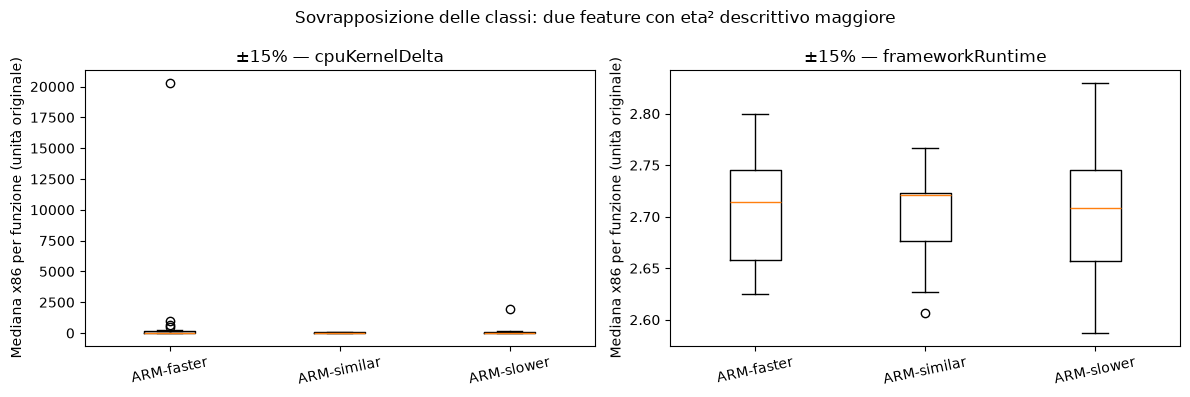


Soglia ±2.5% — statistiche descrittive per feature (non predittive):


,tau,feature,eta2_between_class,between_function_distinct_values,between_function_IQR
26,2.5,frameworkRuntimeDeltas,0.0344,59,0.0620
24,2.5,pageFaultsDelta,0.0317,58,18764.7500
27,2.5,runtime,0.0268,59,3131.1319
17,2.5,userRuntime,0.0268,59,3131.0350
20,2.5,cpuIdleDelta,0.0268,56,9385.0000
21,2.5,cpuIOWaitDelta,0.0249,4,0.0000
19,2.5,cpuKernelDelta,0.0236,20,70.0000
15,2.5,freeMemory,0.0226,59,763507.0000
18,2.5,cpuUserDelta,0.0205,55,3040.0000
25,2.5,utilizedCPUs,0.0163,42,0.0318


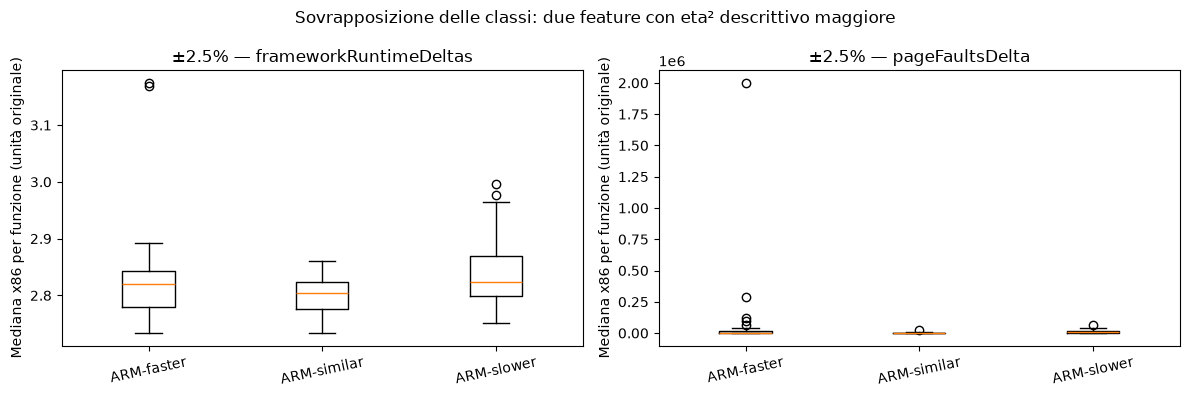

In [17]:
fn_features=x86.groupby('function_name')[PREDICTORS_14].median().loc[truth_index.index]
assert len(fn_features)==59 and fn_features.notna().all().all()
sep_rows=[]
for tau in (15.,2.5):
    y=labels[tau].loc[fn_features.index]
    for feat in PREDICTORS_14:
        v=fn_features[feat].to_numpy(float)
        total=np.sum((v-v.mean())**2)
        between=sum(int((y==cl).sum())*(v[(y==cl).to_numpy()].mean()-v.mean())**2
                    for cl in CLASSES if (y==cl).any())
        sep_rows.append({'tau':tau,'feature':feat,
             'eta2_between_class':(float(between/total) if total>0 else np.nan),
             'between_function_distinct_values':int(fn_features[feat].nunique()),
             'between_function_IQR':float(fn_features[feat].quantile(.75)-fn_features[feat].quantile(.25))})
feature_sep=pd.DataFrame(sep_rows)
for tau in (15.,2.5):
    print(f'\nSoglia ±{tau:g}% — statistiche descrittive per feature (non predittive):')
    display(feature_sep[feature_sep.tau==tau].sort_values('eta2_between_class',ascending=False).round(4))
    leaders=(feature_sep[feature_sep.tau==tau].sort_values('eta2_between_class',ascending=False)
             .dropna(subset=['eta2_between_class']).head(2)['feature'].tolist())
    fig, axes=plt.subplots(1,len(leaders),figsize=(12,4),squeeze=False)
    for ax, feat in zip(axes[0],leaders):
        groups=[fn_features.loc[y==cl,feat].to_numpy(float) for cl in CLASSES]
        ax.boxplot(groups,tick_labels=CLASSES,showfliers=True)
        ax.tick_params(axis='x',rotation=12)
        ax.set_title(f'±{tau:g}% — {feat}')
        ax.set_ylabel('Mediana x86 per funzione (unità originale)')
    fig.suptitle('Sovrapposizione delle classi: due feature con eta² descrittivo maggiore')
    plt.tight_layout();plt.show()


In [18]:
# Vicini per profilo delle funzioni: indicatore geometrico, NON un classificatore calibrato.
ranks=fn_features.rank(axis=0,pct=True).to_numpy(float)
d=np.abs(ranks[:,None,:]-ranks[None,:,:]).mean(axis=2)
np.fill_diagonal(d,np.inf)
nearest=np.argmin(d,axis=1)
fnames=np.asarray(fn_features.index)
for tau in (15.,2.5):
    yi=labels[tau].loc[fnames].to_numpy()
    neighbors=pd.DataFrame({'function_name':fnames,'class':yi,
       'closest_function':fnames[nearest],'closest_class':yi[nearest],
       'mean_rank_L1_distance':d[np.arange(len(fnames)),nearest]})
    neighbors['class_agrees']=neighbors['class']==neighbors['closest_class']
    print(f'±{tau:g}%: vicina più simile con stessa etichetta = '
          f'{int(neighbors.class_agrees.sum())}/59 (diagnostico, non accuracy RF)')
    display(neighbors[~neighbors.class_agrees].sort_values('mean_rank_L1_distance').head(12).round(4))
print('PASS: 59 profili-funzione, nessuna osservazione ARM usata per descrivere le feature')


±15%: vicina più simile con stessa etichetta = 33/59 (diagnostico, non accuracy RF)


,function_name,class,closest_function,closest_class,mean_rank_L1_distance,class_agrees
23,functionbench-matmul,ARM-slower,thumbnailer-node,ARM-similar,0.0430,False
9,compression-node,ARM-similar,graph-bfs-node,ARM-slower,0.0545,False
28,graph-bfs-node,ARM-slower,compression-node,ARM-similar,0.0545,False
16,filehandle,ARM-faster,randomaccess-py,ARM-similar,0.0648,False
49,randomaccess-py,ARM-similar,filehandle,ARM-faster,0.0648,False
56,thumbnailer-py,ARM-similar,hashing-py,ARM-faster,0.0666,False
0,amd_faster,ARM-slower,arm_faster,ARM-faster,0.0726,False
1,arm_faster,ARM-faster,amd_faster,ARM-slower,0.0726,False
32,graph-pagerank,ARM-slower,thumbnailer,ARM-similar,0.0738,False
57,vswarm-aes,ARM-similar,graph-pagerank,ARM-slower,0.0751,False


±2.5%: vicina più simile con stessa etichetta = 19/59 (diagnostico, non accuracy RF)


,function_name,class,closest_function,closest_class,mean_rank_L1_distance,class_agrees
43,memory-rw-node,ARM-similar,thumbnailer-node,ARM-faster,0.0363,False
55,thumbnailer-node,ARM-faster,memory-rw-node,ARM-similar,0.0363,False
12,dna-visualisation-py,ARM-slower,compression-py,ARM-similar,0.0412,False
10,compression-py,ARM-similar,dna-visualisation-py,ARM-slower,0.0412,False
23,functionbench-matmul,ARM-slower,thumbnailer-node,ARM-faster,0.0430,False
27,graph-bfs,ARM-similar,thumbnailer,ARM-faster,0.0448,False
54,thumbnailer,ARM-faster,graph-bfs,ARM-similar,0.0448,False
34,graph-pagerank-py,ARM-slower,compression-py,ARM-similar,0.0521,False
44,memory-rw-py,ARM-slower,compression-py,ARM-similar,0.0551,False
15,dynamichtml,ARM-slower,base64stream,ARM-similar,0.0557,False


PASS: 59 profili-funzione, nessuna osservazione ARM usata per descrivere le feature


## 11 — Validazione annidata: scegliere la quantità di osservazioni senza usare il test

La prova A ha suggerito che 1 osservazione per funzione possa talvolta generalizzare meglio delle 100 originali. **Non possiamo selezionare 1 osservazione guardando la stessa accuracy test che poi riportiamo come finale**. Qui usiamo 5 fold esterni per funzione e, entro ogni training esterno, 3 fold interni per scegliere tra `1, 5, 10, 25, 50, 100` osservazioni. Per ogni candidato ripetiamo due campionamenti indipendenti; stessa RF e stesse 14 feature. Il test esterno rimane ignoto alla selezione. Confrontiamo RF originale (100) e baseline maggioritaria del solo training esterno. Questa è una valutazione incrociata annidata **esplorativa sul medesimo corpus 59**; non sostituisce un nuovo dataset indipendente.

**Nota:** questa cella addestra alcune centinaia di foreste, dunque è più impegnativa delle precedenti. Si può eseguire separatamente, dopo le altre celle.


In [19]:
from sklearn.model_selection import GroupKFold
N_CHOICES=(1,5,10,25,50,100)
INNER_REPEATS=2
INNER_FOLDS=3
OUTER_REPEATS=2
fn_indices={fn:np.flatnonzero(GROUPS==fn) for fn in np.unique(GROUPS)}
assert all(len(v)==100 for v in fn_indices.values())
selection_rows=[]; nested_rows=[]
for tau in (15.,2.5):
    y_lookup=labels[tau]
    y_all=x86.function_name.map(y_lookup).to_numpy()
    for outer,(tr,te) in enumerate(SPLITS,1):
        train_names=np.asarray(sorted(set(GROUPS[tr])))
        outer_names=set(GROUPS[te])
        assert outer_names.isdisjoint(set(train_names))
        # Ogni funzione compare una sola volta nella costruzione dei fold interni.
        inner_cv=list(GroupKFold(n_splits=INNER_FOLDS).split(train_names,groups=train_names))
        scores=[]
        for nobs in N_CHOICES:
            for inner,(subtr,subval) in enumerate(inner_cv,1):
                trnames=train_names[subtr].tolist(); valnames=train_names[subval].tolist()
                assert set(trnames).isdisjoint(set(valnames)|outer_names)
                validx=np.concatenate([fn_indices[fn] for fn in valnames])
                for rep in range(INNER_REPEATS):
                    rng=np.random.default_rng(1000003+int(tau*100)*100000+outer*10000+inner*1000+nobs*10+rep)
                    idx=np.concatenate([rng.choice(fn_indices[fn],size=nobs,replace=False) for fn in trnames])
                    model=RandomForestClassifier(**MODEL_CLASSIFIER)
                    model.fit(x86.iloc[idx][PREDICTORS_14],y_all[idx])
                    p=model.predict(x86.iloc[validx][PREDICTORS_14])
                    acc=get_metrics(collapse_function_votes(x86.iloc[validx],p,y_lookup))['accuracy']
                    scores.append({'n':nobs,'accuracy':acc})
        per_n=pd.DataFrame(scores).groupby('n').accuracy.mean()
        # In caso di pari score, preferiamo 100 osservazioni (protocollo originale).
        chosen=int(sorted(N_CHOICES,key=lambda k:(-per_n.loc[k],-k))[0])
        selection_rows.append({'tau':tau,'outer_fold':outer,'selected_n':chosen,
                                **{f'inner_score_n{k}':float(per_n.loc[k]) for k in N_CHOICES}})
        major=pd.Series(y_all[tr]).value_counts().idxmax()
        base_major=float(np.mean([y_lookup.loc[fn]==major for fn in sorted(outer_names)]))
        original=RandomForestClassifier(**MODEL_CLASSIFIER)
        original.fit(x86.iloc[tr][PREDICTORS_14],y_all[tr])
        op=original.predict(x86.iloc[te][PREDICTORS_14])
        original_acc=get_metrics(collapse_function_votes(x86.iloc[te],op,y_lookup))['accuracy']
        for rep in range(OUTER_REPEATS):
            rng=np.random.default_rng(2000003+int(tau*100)*100000+outer*1000+rep)
            chosenidx=np.concatenate([rng.choice(fn_indices[fn],size=chosen,replace=False) for fn in train_names])
            tuned=RandomForestClassifier(**MODEL_CLASSIFIER)
            tuned.fit(x86.iloc[chosenidx][PREDICTORS_14],y_all[chosenidx])
            pred=tuned.predict(x86.iloc[te][PREDICTORS_14])
            acc=get_metrics(collapse_function_votes(x86.iloc[te],pred,y_lookup))['accuracy']
            nested_rows.append({'tau':tau,'outer_fold':outer,'repeat':rep,
                'chosen_n':chosen,'test_functions':len(outer_names),
                'nested_accuracy':acc,'original_100_accuracy':original_acc,
                'majority_accuracy':base_major})
    print(f'PASS nested CV soglia ±{tau:g}%')
selected_observations=pd.DataFrame(selection_rows)
nested_results=pd.DataFrame(nested_rows)
print('Numero osservazioni scelto autonomamente dai fold interni:')
display(selected_observations[['tau','outer_fold','selected_n']])
print('Valutazione sui fold esterni, selezione effettuata SOLO sul training esterno:')
display(nested_results.groupby('tau')[['nested_accuracy','original_100_accuracy','majority_accuracy']]
        .agg(['mean','std']).round(4))
for tau in (15.,2.5):
    s=nested_results[nested_results.tau==tau]
    print(f'±{tau:g}%: n selezionati=',selected_observations[selected_observations.tau==tau].selected_n.tolist())
    for col in ['nested_accuracy','original_100_accuracy','majority_accuracy']:
        print(f'  {col}: media fold esterni = {100*s[col].mean():.2f}%')
print('PASS: nessuna funzione del test esterno usata per scegliere il numero di campioni')


PASS nested CV soglia ±15%
PASS nested CV soglia ±2.5%
Numero osservazioni scelto autonomamente dai fold interni:


,tau,outer_fold,selected_n
0,15.0,1,1
1,15.0,2,1
2,15.0,3,1
3,15.0,4,1
4,15.0,5,1
5,2.5,1,50
6,2.5,2,50
7,2.5,3,1
8,2.5,4,50
9,2.5,5,1


Valutazione sui fold esterni, selezione effettuata SOLO sul training esterno:


nested_accuracy         original_100_accuracy         majority_accuracy  \
                mean     std                  mean     std              mean   
tau                                                                            
2.5           0.3735  0.1143                0.3394  0.1475            0.3909   
15.0          0.6727  0.1101                0.5970  0.1460            0.6818   

              
         std  
tau           
2.5   0.0940  
15.0  0.1261

±15%: n selezionati= [1, 1, 1, 1, 1]
  nested_accuracy: media fold esterni = 67.27%
  original_100_accuracy: media fold esterni = 59.70%
  majority_accuracy: media fold esterni = 68.18%
±2.5%: n selezionati= [50, 50, 1, 50, 1]
  nested_accuracy: media fold esterni = 37.35%
  original_100_accuracy: media fold esterni = 33.94%
  majority_accuracy: media fold esterni = 39.09%
PASS: nessuna funzione del test esterno usata per scegliere il numero di campioni


## 12 — Profilo mediano e confronto annidato: preprocessing, non nuovo modello

**Ipotesi:** addestrare la stessa RF di Chen con **un unico vettore di mediane x86 per funzione** può ridurre l'effetto delle 100 ripetizioni. Non modifichiamo le 14 feature, gli iperparametri né le etichette. La mediana di ogni feature è calcolata **solo dalle 100 osservazioni x86 della funzione**: non utilizza durate ARM né altre funzioni.

Confrontiamo quattro strategie:

1. `originale_100_vote`: 100 esempi x86 per ogni funzione di training; predizione sulla funzione target tramite voto delle 100 predizioni (protocollo di riferimento).
2. `singolo_1_vote`: 1 osservazione casuale x86 per ogni funzione di training; voto delle 100 predizioni della target.
3. `mediana_vote`: 1 mediana x86 per funzione di training; voto delle 100 predizioni della target.
4. `mediana_mediana`: 1 mediana x86 per funzione di training e 1 mediana x86 per la target (un solo output).

**Confrontabilità:** tutte le strategie dispongono delle 100 osservazioni x86 della target all'atto dell'inferenza (nella modalità `mediana_mediana` vengono aggregate prima della previsione). Non sono predizioni a costo zero: la disponibilità del profilo x86 è una premessa sperimentale da dichiarare.

Usiamo gli stessi 5 fold esterni per funzione. **Dentro ogni training esterno**, una GroupKFold a 3 fold sceglie la strategia sulla base dell'accuracy per funzione; il test esterno è usato soltanto alla fine. La scelta è una variante *di preprocessing/protocollo* e **non equivale alla riproduzione originale di Chen**. Manteniamo una baseline che predice sempre la classe maggioritaria del training esterno.

La strategia `singolo_1_vote` viene ripetuta tre volte per ridurre la dipendenza dalla selezione casuale. I risultati sono esplorativi sul corpus già analizzato: non selezionare a posteriori la strategia usando il test esterno e poi chiamare lo stesso test una conferma indipendente.

In [20]:
# PROVA D — Profili mediani e selezione annidata senza leakage tra funzioni.
# Dipende dalle celle precedenti: x86, truth_index, labels, SPLITS, GROUPS,
# PREDICTORS_14, MODEL_CLASSIFIER, majority_class, collapse_function_votes.

from collections import Counter

FEATURES = list(PREDICTORS_14)
FUNC_MEDIANS = x86.groupby('function_name')[FEATURES].median().sort_index()
assert FUNC_MEDIANS.shape == (59, len(FEATURES))
assert np.isfinite(FUNC_MEDIANS.to_numpy(dtype=float)).all()

PER_FN_INDEX = {fn: np.flatnonzero(GROUPS == fn) for fn in FUNC_MEDIANS.index}
assert all(len(ids) == 100 for ids in PER_FN_INDEX.values())

STRATEGIES = ('originale_100_vote', 'singolo_1_vote',
              'mediana_vote', 'mediana_mediana')
# Tre realizzazioni per il singolo esempio; le altre strategie sono deterministiche.
INNER_REPS_SINGLE = 3
OUTER_REPS_SINGLE = 3
INNER_FOLDS_MEDIAN = 3


def _train_rf(strategy, training_functions, label_lookup, seed):
    """Allena senza feature ARM né esempi di funzioni escluse dal training."""
    names = sorted(training_functions)
    if strategy == 'originale_100_vote':
        ids = np.concatenate([PER_FN_INDEX[fn] for fn in names])
        features = x86.iloc[ids][FEATURES]
        target_labels = x86.iloc[ids].function_name.map(label_lookup).to_numpy()
    elif strategy == 'singolo_1_vote':
        rng = np.random.default_rng(seed)
        ids = [int(rng.choice(PER_FN_INDEX[fn])) for fn in names]
        features = x86.iloc[ids][FEATURES]
        target_labels = x86.iloc[ids].function_name.map(label_lookup).to_numpy()
    elif strategy in ('mediana_vote', 'mediana_mediana'):
        features = FUNC_MEDIANS.loc[names, FEATURES]
        target_labels = label_lookup.loc[names].to_numpy()
    else:
        raise ValueError(strategy)
    assert len(features) == len(target_labels)
    rf = RandomForestClassifier(**MODEL_CLASSIFIER)
    rf.fit(features, target_labels)
    return rf


def _eval_per_fn(rf, strategy, test_functions, label_lookup):
    """Produce esattamente una predizione per funzione (mai per campione)."""
    names = sorted(test_functions)
    if strategy == 'mediana_mediana':
        pred = rf.predict(FUNC_MEDIANS.loc[names, FEATURES])
        return pd.DataFrame({'function_name': names,
                             'true': label_lookup.loc[names].to_numpy(),
                             'pred': pred})
    ids = np.concatenate([PER_FN_INDEX[fn] for fn in names])
    frame = x86.iloc[ids]
    pred = rf.predict(frame[FEATURES])
    result = collapse_function_votes(frame, pred, label_lookup)
    assert len(result) == len(names)
    return result


MEDIAN_SELECTION = []
MEDIAN_OUTER = []
MEDIAN_OOF = []
for tau in (15.0, 2.5):
    lookup = labels[tau]
    for outer_fold, (train_idx, test_idx) in enumerate(SPLITS, 1):
        outer_train = sorted(set(GROUPS[train_idx]))
        outer_test = sorted(set(GROUPS[test_idx]))
        assert not (set(outer_train) & set(outer_test))
        inner_splits = list(GroupKFold(n_splits=INNER_FOLDS_MEDIAN).split(
            np.asarray(outer_train), groups=np.asarray(outer_train)))

        inner_scores = {name: [] for name in STRATEGIES}
        for inner_fold, (inner_train_idx, inner_val_idx) in enumerate(inner_splits, 1):
            names_tr = [outer_train[i] for i in inner_train_idx]
            names_va = [outer_train[i] for i in inner_val_idx]
            assert not (set(names_tr) & set(names_va))
            assert not (set(outer_test) & (set(names_tr) | set(names_va)))
            for strategy in STRATEGIES:
                count = INNER_REPS_SINGLE if strategy == 'singolo_1_vote' else 1
                for repeat in range(count):
                    seed = (20261101 + int(10*tau)*10000 + outer_fold*1000
                            + inner_fold*100 + repeat)
                    model = _train_rf(strategy, names_tr, lookup, seed)
                    result = _eval_per_fn(model, strategy, names_va, lookup)
                    inner_scores[strategy].append(float((result.true == result.pred).mean()))
        avg_inner = {name: float(np.mean(scores)) for name, scores in inner_scores.items()}
        # Tie rule: prefer original protocol. No outer-test information in the decision.
        chosen = max(STRATEGIES, key=lambda name: (avg_inner[name], -STRATEGIES.index(name)))
        MEDIAN_SELECTION.append({'tau': tau, 'outer_fold': outer_fold,
                                 'selected_strategy': chosen, **{
                                     f'inner_{s}': avg_inner[s] for s in STRATEGIES}})

        for strategy in ('originale_100_vote', 'singolo_1_vote',
                         'mediana_vote', 'mediana_mediana', 'scelta_interna', 'majority_baseline'):
            actual = chosen if strategy == 'scelta_interna' else strategy
            count = OUTER_REPS_SINGLE if actual == 'singolo_1_vote' else 1
            for repeat in range(count):
                if strategy == 'majority_baseline':
                    major = lookup.loc[outer_train].value_counts().idxmax()
                    result = pd.DataFrame({
                        'function_name': outer_test,
                        'true': lookup.loc[outer_test].to_numpy(),
                        'pred': [major] * len(outer_test)})
                else:
                    seed = 20261201 + int(tau*10)*10000 + outer_fold*100 + repeat
                    model = _train_rf(actual, outer_train, lookup, seed)
                    result = _eval_per_fn(model, actual, outer_test, lookup)
                assert set(result.function_name) == set(outer_test)
                score = float((result.true == result.pred).mean())
                MEDIAN_OUTER.append({'tau': tau, 'outer_fold': outer_fold,
                                     'strategy': strategy, 'selected': actual,
                                     'repeat': repeat, 'n_test_functions': len(outer_test),
                                     'accuracy': score})
                MEDIAN_OOF.append(result.assign(tau=tau, outer_fold=outer_fold,
                                                strategy=strategy, repeat=repeat))

median_selection = pd.DataFrame(MEDIAN_SELECTION)
median_outer = pd.DataFrame(MEDIAN_OUTER)
median_oof = pd.concat(MEDIAN_OOF, ignore_index=True)

print('Strategie scelte dai fold INTERNI (non dal test):')
display(median_selection[['tau', 'outer_fold', 'selected_strategy']])
print('\nAccuracy per funzione sui fold ESTERNI (media dei fold; ± std tra fold):')
# Media per fold prima di aggregare: non pesare di più le strategie replicate.
per_fold = (median_outer.groupby(['tau', 'strategy', 'outer_fold'])['accuracy']
            .mean().reset_index())
summary_median = (per_fold.groupby(['tau', 'strategy'])['accuracy']
                  .agg(['mean', 'std']).reset_index())
display(summary_median.assign(mean_percent=lambda d: d['mean']*100,
                              std_percent=lambda d: d['std']*100).round(3))

# Aggiungiamo accuracy OOF ponderata per il numero di funzioni testate in ogni fold.
# La strategia scelta è una predizione per funzione per fold (ripetizioni mediate).
pooled_median = (median_outer.assign(w_correct=lambda d: d.accuracy * d.n_test_functions)
                 .groupby(['tau','strategy','outer_fold'])[['w_correct','n_test_functions']]
                 .mean().reset_index()
                 .groupby(['tau','strategy'])[['w_correct','n_test_functions']].sum())
pooled_median['accuracy_pooled'] = pooled_median.w_correct / pooled_median.n_test_functions
print('Accuracy OOF complessiva (59 funzioni, NON ottimizzata sul test):')
display((100*pooled_median[['accuracy_pooled']]).round(2))

assert all(median_outer.groupby(['tau','strategy']).outer_fold.nunique() == 5)
assert len(median_selection) == 10
print('PASS: 59 funzioni x86; nessuna funzione di test usata per scegliere il preprocessing')


Strategie scelte dai fold INTERNI (non dal test):


,tau,outer_fold,selected_strategy
0,15.0,1,singolo_1_vote
1,15.0,2,singolo_1_vote
2,15.0,3,singolo_1_vote
3,15.0,4,mediana_mediana
4,15.0,5,singolo_1_vote
5,2.5,1,singolo_1_vote
6,2.5,2,originale_100_vote
7,2.5,3,singolo_1_vote
8,2.5,4,singolo_1_vote
9,2.5,5,mediana_vote



Accuracy per funzione sui fold ESTERNI (media dei fold; ± std tra fold):


,tau,strategy,mean,std,mean_percent,std_percent
0,2.5,majority_baseline,0.391,0.100,39.091,9.973
1,2.5,mediana_mediana,0.356,0.069,35.606,6.923
2,2.5,mediana_vote,0.374,0.166,37.424,16.620
3,2.5,originale_100_vote,0.339,0.156,33.939,15.649
4,2.5,scelta_interna,0.346,0.152,34.646,15.210
5,2.5,singolo_1_vote,0.368,0.110,36.768,11.034
6,15.0,majority_baseline,0.682,0.134,68.182,13.371
7,15.0,mediana_mediana,0.682,0.158,68.182,15.755
8,15.0,mediana_vote,0.682,0.158,68.182,15.755
9,15.0,originale_100_vote,0.597,0.155,59.697,15.483


Accuracy OOF complessiva (59 funzioni, NON ottimizzata sul test):


accuracy_pooled
tau  strategy                           
2.5  majority_baseline             38.98
     mediana_mediana               35.59
     mediana_vote                  37.29
     originale_100_vote            33.90
     scelta_interna                34.46
     singolo_1_vote                36.72
15.0 majority_baseline             67.80
     mediana_mediana               67.80
     mediana_vote                  67.80
     originale_100_vote            59.32
     scelta_interna                66.10
     singolo_1_vote                66.67

PASS: 59 funzioni x86; nessuna funzione di test usata per scegliere il preprocessing


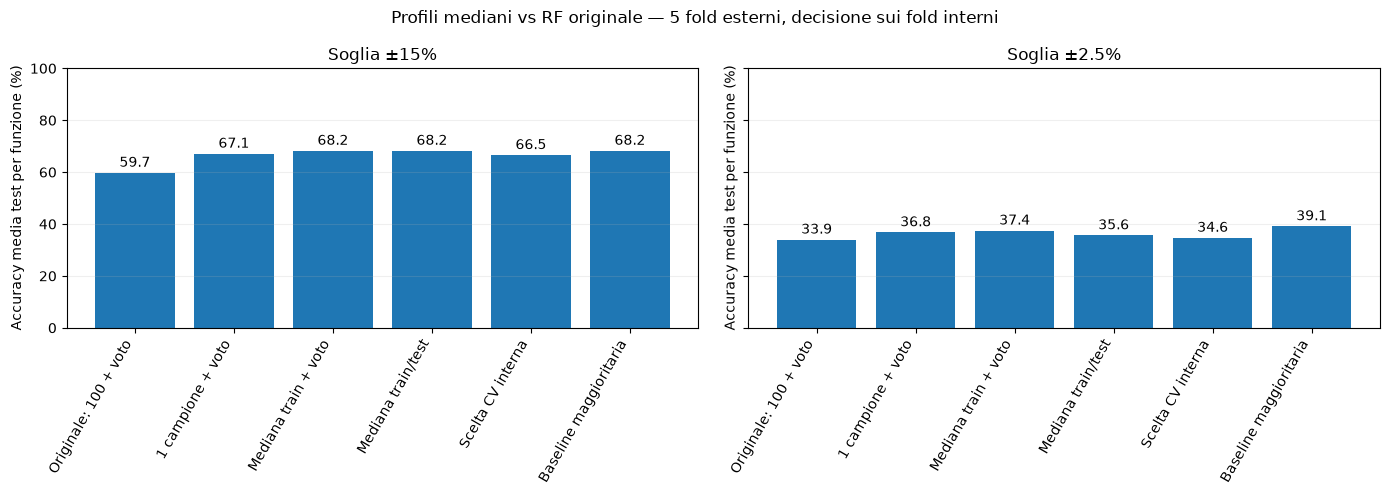

Nota: 80% è un obiettivo, non una soglia garantita. Non riutilizzare questi fold per un tuning post-hoc.


In [21]:
# Visualizzazione compatta: risultati fuori campione, senza scegliere il migliore a posteriori.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
order = list(STRATEGIES) + ['scelta_interna', 'majority_baseline']
readable = {
    'originale_100_vote': 'Originale: 100 + voto',
    'singolo_1_vote': '1 campione + voto',
    'mediana_vote': 'Mediana train + voto',
    'mediana_mediana': 'Mediana train/test',
    'scelta_interna': 'Scelta CV interna',
    'majority_baseline': 'Baseline maggioritaria'
}
for ax, tau in zip(axes, (15., 2.5)):
    sub = summary_median[summary_median.tau == tau].set_index('strategy').loc[order]
    bars = ax.bar(np.arange(len(order)), sub['mean'].to_numpy()*100)
    ax.set_xticks(np.arange(len(order)), [readable[k] for k in order], rotation=60, ha='right')
    ax.set_title(f'Soglia ±{tau:g}%')
    ax.set_ylim(0, 100)
    ax.set_ylabel('Accuracy media test per funzione (%)')
    ax.grid(axis='y', alpha=.2)
    ax.bar_label(bars, fmt='%.1f', padding=2)
fig.suptitle('Profili mediani vs RF originale — 5 fold esterni, decisione sui fold interni')
fig.tight_layout()
plt.show()
print('Nota: 80% è un obiettivo, non una soglia garantita. Non riutilizzare questi fold per un tuning post-hoc.')

,Soglia,Strategia,Accuracy,Balanced accuracy,Macro-F1,Recall ARM-faster,Recall ARM-similar,Recall ARM-slower
0,15.0,originale_100_vote,59.32,31.36,28.83,9.09,85.00,0.00
1,15.0,singolo_1_vote,66.10,32.50,26.53,0.00,97.50,0.00
2,15.0,mediana_vote,67.80,36.67,34.21,0.00,97.50,12.50
3,15.0,mediana_mediana,67.80,35.53,31.85,9.09,97.50,0.00
4,15.0,scelta_interna,66.10,32.50,26.80,0.00,97.50,0.00
5,15.0,majority_baseline,67.80,33.33,26.94,0.00,100.00,0.00
6,2.5,originale_100_vote,33.90,26.50,26.44,46.15,0.00,33.33
7,2.5,singolo_1_vote,40.68,34.58,34.21,38.46,11.11,54.17
8,2.5,mediana_vote,37.29,29.27,27.89,46.15,0.00,41.67
9,2.5,mediana_mediana,35.59,27.99,26.67,42.31,0.00,41.67


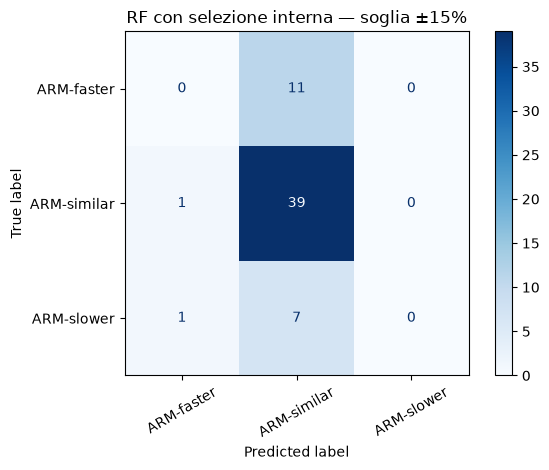

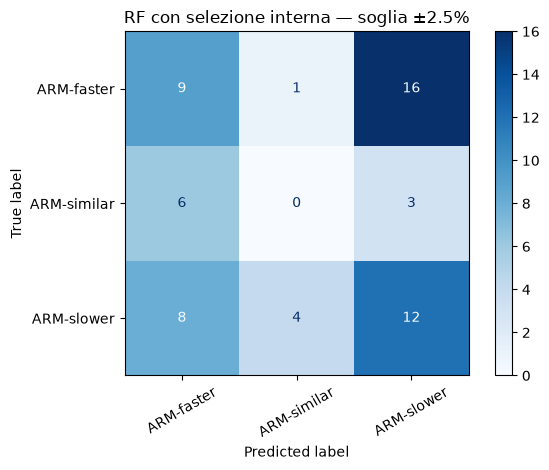

PASS: metriche per classe calcolate sulle 59 funzioni


In [22]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    ConfusionMatrixDisplay,
)

CLASSI = ["ARM-faster", "ARM-similar", "ARM-slower"]

STRATEGIE = [
    "originale_100_vote",
    "singolo_1_vote",
    "mediana_vote",
    "mediana_mediana",
    "scelta_interna",
    "majority_baseline",
]

risultati = []

for tau in (15.0, 2.5):
    for strategia in STRATEGIE:

        # Una predizione per funzione, usando la prima
        # ripetizione quando la strategia è stocastica.
        df = median_oof.loc[
            (median_oof.tau == tau)
            & (median_oof.strategy == strategia)
            & (median_oof.repeat == 0)
        ].copy()

        assert len(df) == 59
        assert df.function_name.nunique() == 59

        y_true = df["true"]
        y_pred = df["pred"]

        precision, recall, f1, support = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                labels=CLASSI,
                zero_division=0,
            )
        )

        risultati.append({
            "Soglia": tau,
            "Strategia": strategia,
            "Accuracy": 100 * accuracy_score(y_true, y_pred),
            "Balanced accuracy": 100 * balanced_accuracy_score(
                y_true, y_pred
            ),
            "Macro-F1": 100 * f1_score(
                y_true,
                y_pred,
                labels=CLASSI,
                average="macro",
                zero_division=0,
            ),
            "Recall ARM-faster": 100 * recall[0],
            "Recall ARM-similar": 100 * recall[1],
            "Recall ARM-slower": 100 * recall[2],
        })

tabella = pd.DataFrame(risultati)

display(tabella.round(2))

# Matrici di confusione della strategia scelta
# dalla validazione interna.
for tau in (15.0, 2.5):

    df = median_oof.loc[
        (median_oof.tau == tau)
        & (median_oof.strategy == "scelta_interna")
        & (median_oof.repeat == 0)
    ]

    ConfusionMatrixDisplay.from_predictions(
        df["true"],
        df["pred"],
        labels=CLASSI,
        cmap="Blues",
        xticks_rotation=30,
    )

    plt.title(f"RF con selezione interna — soglia ±{tau:g}%")
    plt.tight_layout()
    plt.show()

print("PASS: metriche per classe calcolate sulle 59 funzioni")

In [23]:
# ============================================================
# PROVA E - Riequilibrio delle funzioni di training
# ============================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
)

BALANCE_MODES = (
    "originale_100",
    "mediana",
    "sottocamp_2a1",
    "duplicazione",
    "sintetici",
)

BALANCE_INNER_FOLDS = 3
BALANCE_SEED = 20261029


def make_training(names, labels_map, mode, seed):
    """
    Costruisce il training utilizzando soltanto le funzioni
    esplicitamente ricevute.

    I campioni sintetici non vengono mai generati da funzioni
    appartenenti ai fold di validazione o testing.
    """

    names = sorted(names)

    y = labels_map.loc[names].to_numpy()

    X = FUNC_MEDIANS.loc[
        names, PREDICTORS_14
    ].to_numpy(dtype=float)

    # Protocollo originale: 100 osservazioni per funzione.
    if mode == "originale_100":
        idx = np.concatenate([
            PER_FN_INDEX[name] for name in names
        ])

        return (
            x86.iloc[idx][PREDICTORS_14].to_numpy(dtype=float),
            x86.iloc[idx]["function_name"]
            .map(labels_map).to_numpy(),
        )

    # Una mediana reale per funzione.
    if mode == "mediana":
        return X, y

    rng = np.random.default_rng(seed)

    class_ids = {
        cl: np.flatnonzero(y == cl)
        for cl in CLASSES
    }

    assert all(
        len(ids) >= 2 for ids in class_ids.values()
    ), "Troppo poche funzioni per il riequilibrio"

    nmax = max(map(len, class_ids.values()))
    nmin = min(map(len, class_ids.values()))

    # Limitiamo le classi più numerose a 2 volte
    # la numerosità della classe più piccola.
    if mode == "sottocamp_2a1":

        max_keep = 2 * nmin

        selected = np.concatenate([
            rng.choice(
                ids,
                size=min(len(ids), max_keep),
                replace=False,
            )
            for ids in class_ids.values()
        ])

        return X[selected], y[selected]

    # Oversampling tramite copie di profili reali.
    if mode == "duplicazione":

        extra = np.concatenate([
            rng.choice(
                ids,
                size=nmax - len(ids),
                replace=True,
            )
            for ids in class_ids.values()
            if len(ids) < nmax
        ])

        selected = np.concatenate([
            np.arange(len(y)),
            extra,
        ])

        return X[selected], y[selected]

    # Interpolazione sintetica fra funzioni della stessa classe.
    if mode == "sintetici":

        # Lo scaler viene addestrato solo sul training.
        # Serve a calcolare le distanze tra profili.
        scaler = StandardScaler().fit(X)

        Z = scaler.transform(X)

        new_z = []
        new_y = []

        for cl, ids in class_ids.items():

            need = nmax - len(ids)

            if need == 0:
                continue

            neighbors = NearestNeighbors(
                n_neighbors=min(3, len(ids))
            )

            neighbors.fit(Z[ids])

            order = neighbors.kneighbors(
                Z[ids],
                return_distance=False,
            )

            for _ in range(need):

                origin_idx = int(
                    rng.integers(len(ids))
                )

                # Escludiamo il profilo stesso.
                choices = order[origin_idx][1:]

                neighbor_idx = int(
                    rng.choice(choices)
                )

                lam = float(rng.random())

                z = (
                    Z[ids[origin_idx]]
                    + lam * (
                        Z[ids[neighbor_idx]]
                        - Z[ids[origin_idx]]
                    )
                )

                new_z.append(z)
                new_y.append(cl)

        assert new_z

        synth_x = scaler.inverse_transform(
            np.asarray(new_z)
        )

        return (
            np.vstack([X, synth_x]),
            np.concatenate([y, np.asarray(new_y)]),
        )

    raise ValueError(mode)


def predict_on_functions(rf, test_names, labels_map):
    """
    Predice la classe per ogni funzione sconosciuta
    tramite voto sulle sue 100 osservazioni x86.
    """

    indexes = np.concatenate([
        PER_FN_INDEX[name]
        for name in sorted(test_names)
    ])

    rows = x86.iloc[indexes]

    return collapse_function_votes(
        rows,
        rf.predict(rows[PREDICTORS_14]),
        labels_map,
    )


def score_macro_f1(table):
    return float(
        f1_score(
            table["true"],
            table["pred"],
            labels=list(CLASSES),
            average="macro",
            zero_division=0,
        )
    )


balance_predictions = []
balance_selections = []

for tau in (15.0, 2.5):

    lookup = labels[tau]

    for outer, (train_idx, test_idx) in enumerate(SPLITS, 1):

        train_names = np.asarray(
            sorted(set(GROUPS[train_idx]))
        )

        test_names = sorted(
            set(GROUPS[test_idx])
        )

        assert set(train_names).isdisjoint(test_names)

        train_labels = lookup.loc[
            train_names
        ].to_numpy()

        # Validazione interna: solo funzioni di training.
        inner = StratifiedKFold(
            n_splits=BALANCE_INNER_FOLDS,
            shuffle=True,
            random_state=(
                BALANCE_SEED + outer + int(tau * 10)
            ),
        )

        scores = {
            mode: [] for mode in BALANCE_MODES
        }

        for inner_fold, (subtr, val) in enumerate(
            inner.split(train_names, train_labels), 1
        ):

            tr_names = train_names[subtr]
            val_names = train_names[val]

            assert set(tr_names).isdisjoint(
                set(val_names) | set(test_names)
            )

            for mi, mode in enumerate(BALANCE_MODES):

                seed = (
                    BALANCE_SEED
                    + int(tau * 100) * 10000
                    + outer * 1000
                    + inner_fold * 10
                    + mi
                )

                features, target = make_training(
                    tr_names,
                    lookup,
                    mode,
                    seed,
                )

                rf = RandomForestClassifier(
                    **MODEL_CLASSIFIER
                )

                features_df = pd.DataFrame(
                    features,
                    columns=PREDICTORS_14,
                )
                
                rf.fit(features_df, target)

                val_pred = predict_on_functions(
                    rf,
                    val_names,
                    lookup,
                )

                scores[mode].append(
                    score_macro_f1(val_pred)
                )

        avg = {
            mode: float(np.mean(scores[mode]))
            for mode in BALANCE_MODES
        }

        # La scelta usa esclusivamente i fold interni.
        # In caso di parità preferiamo il protocollo originale.
        selected = max(
            BALANCE_MODES,
            key=lambda m: (
                avg[m],
                -BALANCE_MODES.index(m),
            ),
        )

        balance_selections.append({
            "tau": tau,
            "outer_fold": outer,
            "scelta": selected,
            "macro_f1_inner": avg[selected],
        })

        outer_results = {}

        # Valutazione delle singole strategie sul test esterno.
        for mi, mode in enumerate(BALANCE_MODES):

            seed = (
                BALANCE_SEED
                + int(tau * 100) * 10000
                + outer * 100
                + mi
            )

            features, target = make_training(
                train_names,
                lookup,
                mode,
                seed,
            )

            rf = RandomForestClassifier(
                **MODEL_CLASSIFIER
            )
            
            # Conserviamo gli stessi valori e lo stesso ordine
            # delle 14 caratteristiche, aggiungendo i nomi.
            features_df = pd.DataFrame(
                features,
                columns=PREDICTORS_14,
            )
            
            rf.fit(features_df, target)

            result = predict_on_functions(
                rf,
                test_names,
                lookup,
            )

            outer_results[mode] = result

            balance_predictions.append(
                result.assign(
                    tau=tau,
                    outer_fold=outer,
                    method=mode,
                )
            )

        # Valutazione della strategia selezionata internamente.
        balance_predictions.append(
            outer_results[selected].copy().assign(
                tau=tau,
                outer_fold=outer,
                method="scelta_interna",
            )
        )

        # Baseline maggioritaria, calcolata sul training.
        majority = lookup.loc[
            train_names
        ].value_counts().idxmax()

        baseline = pd.DataFrame({
            "function_name": test_names,
            "true": lookup.loc[test_names].to_numpy(),
            "pred": [majority] * len(test_names),
        })

        balance_predictions.append(
            baseline.assign(
                tau=tau,
                outer_fold=outer,
                method="baseline_maggioritaria",
            )
        )

balance_oof = pd.concat(
    balance_predictions,
    ignore_index=True,
)

summary_rows = []

for (tau, method), frame in balance_oof.groupby(
    ["tau", "method"]
):

    assert len(frame) == 59
    assert frame.function_name.nunique() == 59

    recall = recall_score(
        frame.true,
        frame.pred,
        labels=list(CLASSES),
        average=None,
        zero_division=0,
    )

    summary_rows.append({
        "soglia": tau,
        "metodo": method,
        "accuracy": 100 * accuracy_score(
            frame.true, frame.pred
        ),
        "balanced_accuracy": 100 * balanced_accuracy_score(
            frame.true, frame.pred
        ),
        "macro_f1": 100 * score_macro_f1(frame),
        "recall_ARM_faster": 100 * recall[0],
        "recall_ARM_similar": 100 * recall[1],
        "recall_ARM_slower": 100 * recall[2],
    })

print(
    "===== RISULTATI: 59 FUNZIONI MAI VISTE "
    "NEL RELATIVO TRAINING ====="
)

display(
    pd.DataFrame(summary_rows).round(2)
)

print(
    "===== STRATEGIE SCELTE DAI FOLD INTERNI ====="
)

display(
    pd.DataFrame(balance_selections)
)

print(
    "PASS: 5 fold esterni, 3 fold interni; "
    "nessuna funzione di test nel training"
)

===== RISULTATI: 59 FUNZIONI MAI VISTE NEL RELATIVO TRAINING =====


,soglia,metodo,accuracy,balanced_accuracy,macro_f1,recall_ARM_faster,recall_ARM_similar,recall_ARM_slower
0,2.5,baseline_maggioritaria,38.98,29.91,24.76,73.08,0.00,16.67
1,2.5,duplicazione,35.59,27.99,27.98,42.31,0.00,41.67
2,2.5,mediana,37.29,29.27,27.89,46.15,0.00,41.67
3,2.5,originale_100,33.90,26.50,26.44,46.15,0.00,33.33
4,2.5,scelta_interna,33.90,26.71,26.41,38.46,0.00,41.67
5,2.5,sintetici,30.51,23.93,23.49,38.46,0.00,33.33
6,2.5,sottocamp_2a1,32.20,30.27,29.62,26.92,22.22,41.67
7,15.0,baseline_maggioritaria,67.80,33.33,26.94,0.00,100.00,0.00
8,15.0,duplicazione,52.54,25.83,23.22,0.00,77.50,0.00
9,15.0,mediana,67.80,36.67,34.21,0.00,97.50,12.50


===== STRATEGIE SCELTE DAI FOLD INTERNI =====


,tau,outer_fold,scelta,macro_f1_inner
0,15.0,1,originale_100,0.322743
1,15.0,2,sintetici,0.298060
2,15.0,3,duplicazione,0.429998
3,15.0,4,sottocamp_2a1,0.330702
4,15.0,5,mediana,0.382367
5,2.5,1,sottocamp_2a1,0.363454
6,2.5,2,sintetici,0.358344
7,2.5,3,sottocamp_2a1,0.364132
8,2.5,4,originale_100,0.336340
9,2.5,5,originale_100,0.287424


PASS: 5 fold esterni, 3 fold interni; nessuna funzione di test nel training


## PROVA F — Rapporti di sottocampionamento 1:1, 2:1, 3:1, 4:1, ripetizioni e CV annidata

**Obiettivo.** Verificare se cambiare la proporzione delle classi nel *solo training* migliori il riconoscimento delle preferenze ARM-faster e ARM-slower, senza modificare i parametri della Random Forest.

* Soglie ±15% e ±2,5%. La stessa funzione non compare mai contemporaneamente in training e test.
* **Cinque GroupKFold esterni** già congelati nelle celle precedenti; **tre StratifiedKFold interni** costruiti solamente con le funzioni del training esterno.
* Ogni sottocampionamento viene ripetuto con **tre semi predeterminati**, anche nella validazione interna; test sempre su 100 osservazioni x86/funzione e voto per funzione.
* Selezione del rapporto tramite **macro-F1 interno**; confronti esterni dei singoli rapporti sono *esplorativi*, mentre `scelta_interna` evita di scegliere direttamente dal test esterno.
* `mediana` (una riga per funzione senza bilanciamento), `originale_100` e classe maggioritaria restano come baseline. Nessuna osservazione ARM entra nel vettore di input.
* Le ripetizioni delle stesse funzioni non sono dataset indipendenti: non interpretare la deviazione standard fra semi come intervallo di confidenza statistico.

**Durata:** questa cella addestra centinaia di foreste; per interrompere usare il comando Interrupt del kernel e riavviare la sola cella.

In [24]:
# PROVA F — Ricerca di rapporti di sottocampionamento sui profili mediani.
# Non modifica PREDICTORS_14 né MODEL_CLASSIFIER; non esporta/sovrascrive CSV.
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

RATIO_CHOICES = (1, 2, 3, 4)
RATIO_INNER_REPEATS = 3
RATIO_OUTER_REPEATS = 3
RATIO_INNER_FOLDS = 3
RATIO_SEED = 20261030


def _ratio_training_data(training_functions, label_lookup, ratio, seed):
    """Sottocampiona SOLO funzioni del training; restituisce una mediana/funzione."""
    names = np.asarray(sorted(training_functions))
    labels_train = label_lookup.loc[names].to_numpy()
    rng = np.random.default_rng(seed)
    classes_present = {cl: np.flatnonzero(labels_train == cl) for cl in CLASSES}
    assert all(len(ix) >= 1 for ix in classes_present.values()), 'Classe assente nel training'
    n_min = min(map(len, classes_present.values()))
    selected = np.concatenate([
        rng.choice(ix, size=min(len(ix), ratio * n_min), replace=False)
        for ix in classes_present.values()
    ])
    rng.shuffle(selected)
    return (FUNC_MEDIANS.loc[names[selected], PREDICTORS_14],
            label_lookup.loc[names[selected]].to_numpy())


def _fit_ratio(training_functions, label_lookup, mode, seed):
    names = sorted(training_functions)
    if mode == 'originale_100':
        ids = np.concatenate([PER_FN_INDEX[n] for n in names])
        X = x86.iloc[ids][PREDICTORS_14]
        y = x86.iloc[ids].function_name.map(label_lookup).to_numpy()
    elif mode == 'mediana':
        X = FUNC_MEDIANS.loc[names, PREDICTORS_14]
        y = label_lookup.loc[names].to_numpy()
    else:
        assert isinstance(mode, int) and mode in RATIO_CHOICES
        X, y = _ratio_training_data(names, label_lookup, mode, seed)
    rf = RandomForestClassifier(**MODEL_CLASSIFIER)
    rf.fit(X, y)
    return rf


def _predict_ratio(rf, testing_functions, label_lookup):
    names = sorted(testing_functions)
    idx = np.concatenate([PER_FN_INDEX[n] for n in names])
    sample_rows = x86.iloc[idx]
    out = collapse_function_votes(
        sample_rows,
        rf.predict(sample_rows[PREDICTORS_14]),
        label_lookup,
    )
    assert len(out) == len(names) and set(out.function_name) == set(names)
    return out


def _ratio_macro_f1(frame):
    return float(f1_score(frame.true, frame.pred, labels=list(CLASSES),
                          average='macro', zero_division=0))


RATIO_INNER = []
RATIO_SELECTION = []
RATIO_OOF = []
for tau in (15.0, 2.5):
    lookup = labels[tau]
    for outer_fold, (idx_train, idx_test) in enumerate(SPLITS, 1):
        outer_train = np.asarray(sorted(set(GROUPS[idx_train])))
        outer_test = sorted(set(GROUPS[idx_test]))
        assert set(outer_train).isdisjoint(outer_test)
        y_outer = lookup.loc[outer_train].to_numpy()
        inner = StratifiedKFold(n_splits=RATIO_INNER_FOLDS,
                                shuffle=True, random_state=RATIO_SEED + int(tau*10) + outer_fold)
        folds_inner = list(inner.split(outer_train, y_outer))
        assert all(set(outer_train[tr]).isdisjoint(set(outer_train[va]))
                   for tr, va in folds_inner)
        scores = {ratio: [] for ratio in RATIO_CHOICES}
        for inner_fold, (tr_idx, va_idx) in enumerate(folds_inner, 1):
            tr_names = outer_train[tr_idx].tolist()
            va_names = outer_train[va_idx].tolist()
            assert not(set(tr_names) & (set(va_names) | set(outer_test)))
            for ratio in RATIO_CHOICES:
                for rep in range(RATIO_INNER_REPEATS):
                    seed = (RATIO_SEED + int(tau*100)*10000 + outer_fold*1000
                            + inner_fold*100 + ratio*10 + rep)
                    rf = _fit_ratio(tr_names, lookup, ratio, seed)
                    val = _predict_ratio(rf, va_names, lookup)
                    scores[ratio].append(_ratio_macro_f1(val))
        avg = {r: float(np.mean(v)) for r,v in scores.items()}
        # Parità: minore intervento sui dati => rapporto più alto.
        selected_ratio = max(RATIO_CHOICES, key=lambda r: (avg[r], r))
        RATIO_SELECTION.append({'tau': tau, 'outer_fold':outer_fold,
                                'selected_ratio':selected_ratio,
                                **{f'inner_macro_F1_ratio_{r}':avg[r] for r in RATIO_CHOICES}})
        for r in RATIO_CHOICES:
            RATIO_INNER.append({'tau':tau,'outer_fold':outer_fold,'ratio':r,
                                'inner_macro_F1_mean':avg[r]})
        # Test esterno: nessuna scelta effettuata osservando le sue etichette.
        # 'scelta_interna' applica sempre il rapporto scelto in questo fold.
        for repeat in range(RATIO_OUTER_REPEATS):
            seed = RATIO_SEED + int(tau*100)*100000 + outer_fold*1000 + repeat
            for mode in ('originale_100', 'mediana', *RATIO_CHOICES, 'scelta_interna', 'majority_baseline'):
                if mode == 'majority_baseline':
                    majority = lookup.loc[outer_train].value_counts().idxmax()
                    result = pd.DataFrame({'function_name':outer_test,
                                           'true':lookup.loc[outer_test].to_numpy(),
                                           'pred':[majority]*len(outer_test)})
                else:
                    chosen = selected_ratio if mode == 'scelta_interna' else mode
                    rf = _fit_ratio(outer_train, lookup, chosen,
                                    seed + (chosen if isinstance(chosen, int) else 0))
                    result = _predict_ratio(rf, outer_test, lookup)
                RATIO_OOF.append(result.assign(tau=tau, outer_fold=outer_fold,
                                               repeat=repeat, method=str(mode)))
        print(f'±{tau:g}% fold {outer_fold}/5: rapporto CV interno selezionato = {selected_ratio}',flush=True)

ratio_oof = pd.concat(RATIO_OOF, ignore_index=True)
ratio_selection = pd.DataFrame(RATIO_SELECTION)
ratio_inner = pd.DataFrame(RATIO_INNER)

ratio_rows = []
for (tau, mode, rep), frame in ratio_oof.groupby(['tau','method','repeat']):
    assert len(frame) == 59 and frame.function_name.nunique() == 59
    rc = recall_score(frame.true, frame.pred, labels=list(CLASSES),
                      average=None, zero_division=0)
    ratio_rows.append({'tau':tau, 'method':mode, 'repeat':rep,
                       'accuracy':accuracy_score(frame.true,frame.pred)*100,
                       'balanced_accuracy':balanced_accuracy_score(frame.true,frame.pred)*100,
                       'macro_F1':_ratio_macro_f1(frame)*100,
                       'recall_ARM_faster':rc[0]*100,
                       'recall_ARM_similar':rc[1]*100,
                       'recall_ARM_slower':rc[2]*100})
ratio_metrics_by_repeat = pd.DataFrame(ratio_rows)
ratio_metrics_mean = ratio_metrics_by_repeat.groupby(['tau','method'],as_index=False).agg(
    accuracy_mean=('accuracy','mean'), accuracy_std=('accuracy','std'),
    balanced_mean=('balanced_accuracy','mean'), macro_F1_mean=('macro_F1','mean'),
    recall_ARM_faster_mean=('recall_ARM_faster','mean'),
    recall_ARM_similar_mean=('recall_ARM_similar','mean'),
    recall_ARM_slower_mean=('recall_ARM_slower','mean'),
)
print('\n===== RISULTATI PER SOGGIA / STRATEGIA (media sui 3 semi; ogni seme testa 59 funzioni) =====')
display(ratio_metrics_mean.round(2).sort_values(['tau','method']))
print('\n===== VARIABILITÀ TRA SEMI (non sono campioni di test indipendenti) =====')
display(ratio_metrics_by_repeat.round(2).sort_values(['tau','method','repeat']))
print('\n===== RAPPORTI SCELTI DAI FOLD INTERNI =====')
display(ratio_selection.round(3))
print('\n===== PUNTEGGI CV INTERNA =====')
display(ratio_inner.pivot(index=['tau','outer_fold'],columns='ratio',values='inner_macro_F1_mean').round(3))
print('PASS: 5 fold esterni per funzione, 3 fold interni stratificati, 3 semi, nessun leakage')


±15% fold 1/5: rapporto CV interno selezionato = 2
±15% fold 2/5: rapporto CV interno selezionato = 2
±15% fold 3/5: rapporto CV interno selezionato = 2
±15% fold 4/5: rapporto CV interno selezionato = 3
±15% fold 5/5: rapporto CV interno selezionato = 2
±2.5% fold 1/5: rapporto CV interno selezionato = 3
±2.5% fold 2/5: rapporto CV interno selezionato = 3
±2.5% fold 3/5: rapporto CV interno selezionato = 2
±2.5% fold 4/5: rapporto CV interno selezionato = 4
±2.5% fold 5/5: rapporto CV interno selezionato = 4

===== RISULTATI PER SOGGIA / STRATEGIA (media sui 3 semi; ogni seme testa 59 funzioni) =====


,tau,method,accuracy_mean,accuracy_std,balanced_mean,macro_F1_mean,recall_ARM_faster_mean,recall_ARM_similar_mean,recall_ARM_slower_mean
0,2.5,1,24.29,3.53,26.84,23.28,28.21,37.04,15.28
1,2.5,2,29.38,2.59,24.62,24.45,35.90,7.41,30.56
2,2.5,3,31.07,0.98,24.39,23.29,38.46,0.00,34.72
3,2.5,4,32.20,2.94,25.21,23.90,42.31,0.00,33.33
4,2.5,majority_baseline,38.98,0.00,29.91,24.76,73.08,0.00,16.67
5,2.5,mediana,37.29,0.00,29.27,27.89,46.15,0.00,41.67
6,2.5,originale_100,33.90,0.00,26.50,26.44,46.15,0.00,33.33
7,2.5,scelta_interna,31.07,3.53,24.39,23.39,38.46,0.00,34.72
8,15.0,1,32.77,12.02,40.48,30.20,27.27,27.50,66.67
9,15.0,2,49.15,1.69,42.22,39.64,33.33,55.83,37.50



===== VARIABILITÀ TRA SEMI (non sono campioni di test indipendenti) =====


,tau,method,repeat,accuracy,balanced_accuracy,macro_F1,recall_ARM_faster,recall_ARM_similar,recall_ARM_slower
0,2.5,1,0,27.12,28.21,25.88,34.62,33.33,16.67
1,2.5,1,1,25.42,31.98,25.53,15.38,55.56,25.00
2,2.5,1,2,20.34,20.33,18.43,34.62,22.22,4.17
3,2.5,2,0,27.12,21.05,20.50,42.31,0.00,20.83
4,2.5,2,1,32.20,27.74,27.81,34.62,11.11,37.50
5,2.5,2,2,28.81,25.07,25.05,30.77,11.11,33.33
6,2.5,3,0,30.51,23.93,22.58,38.46,0.00,33.33
7,2.5,3,1,30.51,24.04,23.08,34.62,0.00,37.50
8,2.5,3,2,32.20,25.21,24.21,42.31,0.00,33.33
9,2.5,4,0,28.81,22.65,21.78,34.62,0.00,33.33



===== RAPPORTI SCELTI DAI FOLD INTERNI =====


,tau,outer_fold,selected_ratio,inner_macro_F1_ratio_1,inner_macro_F1_ratio_2,inner_macro_F1_ratio_3,inner_macro_F1_ratio_4
0,15.0,1,2,0.230,0.295,0.244,0.252
1,15.0,2,2,0.252,0.283,0.252,0.238
2,15.0,3,2,0.269,0.322,0.257,0.270
3,15.0,4,3,0.265,0.326,0.327,0.300
4,15.0,5,2,0.381,0.409,0.362,0.256
5,2.5,1,3,0.360,0.328,0.373,0.362
6,2.5,2,3,0.329,0.332,0.364,0.343
7,2.5,3,2,0.327,0.379,0.324,0.314
8,2.5,4,4,0.262,0.304,0.279,0.354
9,2.5,5,4,0.206,0.282,0.303,0.313



===== PUNTEGGI CV INTERNA =====


ratio                1      2      3      4
tau  outer_fold                            
2.5  1           0.360  0.328  0.373  0.362
     2           0.329  0.332  0.364  0.343
     3           0.327  0.379  0.324  0.314
     4           0.262  0.304  0.279  0.354
     5           0.206  0.282  0.303  0.313
15.0 1           0.230  0.295  0.244  0.252
     2           0.252  0.283  0.252  0.238
     3           0.269  0.322  0.257  0.270
     4           0.265  0.326  0.327  0.300
     5           0.381  0.409  0.362  0.256

PASS: 5 fold esterni per funzione, 3 fold interni stratificati, 3 semi, nessun leakage
